## 🤖 Complete Plant Simulation Specification: Discrete-Time Open-Loop Asymmetric 4-Omni Robot Model

This cell specifies the comprehensive mathematical framework for the 4-wheel omni-directional mobile robot simulation. The architecture accounts for **asymmetric wheel layouts**, **dynamic multi-axis weight transfer (pitch and roll)**, **non-calibrated hardware parameters**, and **LuGre bristle floor friction boundaries** evaluated via **implicit (backward Euler) discrete-time updates** at a fixed sampling interval $\Delta T = 1\text{ ms}$ ($1\text{ kHz}$ loop rate).

---
<details>
<summary><b> Open this for the full specification of the simulation equations</b></summary>


### 1. Parameters & Variable Definitions

#### 🛠️ Hardware & Structural Parameters (Henry Calibrated Constants)
* $M_r$ : Total mass of the robot chassis
* $J_{zz}$: Rotational mass moment of inertia around vertical Z-axis
* $J_w $: Rotational moment of inertia of a wheel/rotor assembly
* $R_b$ : Geometric base radius from the base centre to the wheel contact points
* $r $: Operating radius of omni-wheel tires
* $\alpha_f$ = : Front wheel mounting angle relative to local $+x_r$ axis
* $\alpha_b $= : Rear wheel mounting angle relative to local $+x_r$ axis
* $h$: Height of Center of Mass (CoM) above ground plane
* $y_{cg}$ : Center of Mass position forward of the base centre (0 for now: centred)
* $V_{max}$ : Supply voltage saturation limit
* $R$ , $L_m$ : DC motor armature winding resistance and inductance
* $K_t $= $K_b$ : Electromechanical torque and back-EMF constants
* $C_{rr}$ : Floor-tire rolling resistance coefficient
* $\mu_s$ , $\mu_k$ : Static and kinetic floor-tire friction coefficients
* $\delta$ : LuGre presliding bristle deflection limit ($2\,\mu\text{m}$)
* $\zeta $: LuGre bristle damping ratio fraction against rim inertia
* $v_\sigma$ : Slip velocity threshold where bristle damping fades out
* $v_c $: Creep regularization velocity preventing division by zero at rest
* $\alpha_d $: Stribeck exponential decay rate from static to kinetic friction
* $\varepsilon $: Hyperbolic tangent smoothing speed for rolling resistance drag
* $\epsilon_{tol}$, $n_{max}$ : Tolerance on the slip change, and the most solves per step, for the wheel solve (`implicit_tol`, `implicit_max_iter`)

---

### 2. Signal Tracker Definitions

At each sample time step $k$, the discrete simulation cycle processes the following variables:

#### System Inputs
* $\mathbf{V}_k = [V_{1,k}, V_{2,k}, V_{3,k}, V_{4,k}]^\top$: Armature terminal voltage commands (Volts), clipped to $\pm V_{max}$.

#### Tracked Memory Integration States
* $\mathbf{I}_k = [i_{1,k}, i_{2,k}, i_{3,k}, i_{4,k}]^\top$: Motor armature currents (Amperes).
* $\mathbf{\Omega}_k = [\omega_{1,k}, \omega_{2,k}, \omega_{3,k}, \omega_{4,k}]^\top$: Wheel angular velocities (rad/s).
* $\mathbf{z}_k = [z_{1,k}, z_{2,k}, z_{3,k}, z_{4,k}]^\top$: LuGre normalized bristle deflections (meters / normalized).
* $\mathbf{\dot{X}}_{r,k} = [\dot{x}_{r,k}, \dot{y}_{r,k}, \dot{\theta}_{k}]^\top$: Local chassis velocities (m/s Right, m/s Forward, rad/s Yaw), derived from the global velocities.
* $\mathbf{\ddot{X}}_{r,k-1} = [a_{x,r,k-1}, a_{y,r,k-1}, \alpha_{r,k-1}]^\top$: Historical chassis accelerations from step $k-1$ (m/s², m/s², rad/s²).
* $\mathbf{\dot{X}}_{g,k} = [\dot{x}_{g,k}, \dot{y}_{g,k}, \dot{\theta}_{g,k}]^\top$: Global room frame velocities (m/s, m/s, rad/s): the advanced velocity state, since Newton's law holds in this fixed frame.
* $\mathbf{X}_{g,k} = [x_k, y_k, \theta_k]^\top$: Global room frame navigation coordinates (meters, meters, radians).

---

### 3. Kinematic Mapping Matrix $\mathbf{H}$ (Body Frame: $+x_r$ Right, $+y_r$ Forward)

The chassis motion is measured about the Center of Mass, $y_{cg}$ forward of the base centre; each wheel's yaw lever about it is $R_b - y_{cg}\sin\beta_i$ ($R_b$ while the CoG is centred):

$$\mathbf{v}_{w,k} = \mathbf{H} \mathbf{\dot{X}}_{r,k}, \qquad \mathbf{H} = \begin{bmatrix} -\sin\alpha_f & \cos\alpha_f & R_b - y_{cg}\sin\alpha_f \\ -\sin\alpha_f & -\cos\alpha_f & R_b - y_{cg}\sin\alpha_f \\ \sin\alpha_b & -\cos\alpha_b & R_b + y_{cg}\sin\alpha_b \\ \sin\alpha_b & \cos\alpha_b & R_b + y_{cg}\sin\alpha_b \end{bmatrix}$$

$J_{zz}$ is the yaw inertia about the Center of Mass, so the mass matrix is $\mathbf{M} = \text{diag}(M_r, M_r, J_{zz})$.

---

### 4. Dynamic Normal Load Redistribution

With $+x_r$ Right (strafing) and $+y_r$ Forward (longitudinal):
$$y_f = R_b \sin\alpha_f = 0.03975\text{ m}, \qquad y_b = R_b \sin\alpha_b = 0.05622\text{ m}, \qquad L = y_f + y_b = 0.09597\text{ m}$$
$$x_f = R_b \cos\alpha_f = 0.06885\text{ m}, \qquad x_b = R_b \cos\alpha_b = 0.05622\text{ m}, \qquad \Sigma X^2 = x_f^2 + x_b^2 = 0.007901\text{ m}^2$$
The front and rear axle distances from the Center of Mass (equal to $y_f$, $y_b$ while it is centred):
$$y_{f,cg} = y_f - y_{cg}, \qquad y_{b,cg} = y_b + y_{cg}$$

#### Static Normal Force Distribution at Rest (values with the CoG centred)
$$F_{n,\text{front, static}} = \frac{M_r g y_{b,cg}}{2 L} = 7.752\text{ N}, \qquad F_{n,\text{rear, static}} = \frac{M_r g y_{f,cg}}{2 L} = 5.482\text{ N}$$

#### Dynamic Weight Shifts (Pitch due to $a_{y,\text{past}}$, Roll due to $a_{x,\text{past}}$)
$$\Delta F_{n,y} = \frac{M_r a_{y,\text{past}} h}{2 L}, \qquad \Delta F_{n,x,\text{front}} = \frac{x_f}{\Sigma X^2} \frac{M_r a_{x,\text{past}} h y_{b,cg}}{L}, \qquad \Delta F_{n,x,\text{rear}} = \frac{x_b}{\Sigma X^2} \frac{M_r a_{x,\text{past}} h y_{f,cg}}{L}$$

$$\mathbf{F}_{n,k} = \begin{bmatrix} F_{n,\text{front, static}} - \Delta F_{n,y} - \Delta F_{n,x,\text{front}} + w_{F,1} \\ F_{n,\text{front, static}} - \Delta F_{n,y} + \Delta F_{n,x,\text{front}} + w_{F,2} \\ F_{n,\text{rear, static}} + \Delta F_{n,y} + \Delta F_{n,x,\text{rear}} + w_{F,3} \\ F_{n,\text{rear, static}} + \Delta F_{n,y} - \Delta F_{n,x,\text{rear}} + w_{F,4} \end{bmatrix}$$

---

### 5. Motor, LuGre Bristle Friction & Discrete Integration

The motor current, wheel speed and bristle deflection of each wheel change faster than $\Delta T$ (the bristles' presliding and the motor's $L_m/R$), so they are discretised with **backward (implicit) Euler**, $\frac{dx}{dt} \approx \frac{x_{k+1} - x_k}{\Delta T}$ with the right-hand side at step $k+1$, which stays stable at any $\Delta T$. The three are solved together for each wheel (item 7). The chassis then follows with Forward Euler.

1. **Supply Limit and Motor Armature Current:**
   $$V_{i,k} = \text{clip}\left(V_{cmd,i,k}, -V_{max}, V_{max}\right), \qquad L_m \frac{i_{i,k+1} - i_{i,k}}{\Delta T} = V_{i,k} - R\, i_{i,k+1} - K_b\, \omega_{i,k+1}, \qquad T_{m,i,k+1} = K_t\, i_{i,k+1}$$

2. **Contact Slip Velocity along Rolling Axis** (chassis contact speed of step $k$, new wheel speed):
   $$v_{s,i,k+1} = (\mathbf{H} \mathbf{\dot{X}}_{r,k})_i - r \omega_{i,k+1}$$

3. **Smoothed Rolling Resistance Drag:**
   $$T_{\text{roll},i,k} = C_{rr} F_{n,i,k} r \tanh\left( \frac{\omega_{i,k}}{\varepsilon} \right)$$

4. **Stribeck Friction Curve:**
   $$\mu_{d,i} = \mu_k + (\mu_s - \mu_k) e^{-\alpha_d |v_{s,i,k+1}|}$$

5. **Backward Euler Bristle Update ($\Delta T = 1\text{ ms}$):**
   $$\delta \, \frac{z_{i,k+1} - z_{i,k}}{\Delta T} = v_{s,i,k+1} - \frac{\mu_s}{\mu_{d,i}} \sqrt{v_{s,i,k+1}^2 + v_c^2}\; z_{i,k+1}$$

6. **Net Tractive Floor Force:**
   $$\sigma_{1,i} = 2 \zeta \sqrt{ \frac{\mu_s F_{n,i,k}}{\delta} \frac{J_w}{r^2} } e^{-(v_{s,i,k+1} / v_\sigma)^2}$$
   $$F_{i,k+1} = -\left( \mu_s F_{n,i,k} z_{i,k+1} + \sigma_{1,i} \delta \frac{z_{i,k+1} - z_{i,k}}{\Delta T} + \sigma_2 v_{s,i,k+1} \right)$$
   In sliding the bristles settle within a step, $F_i = -\text{sign}(v_{s,i})\, \mu_{d,i} F_{n,i}$: the Coulomb–Stribeck law.

7. **Unified Wheel Speed Update (solved with items 1, 5 and 6):**
   $$J_w \frac{\omega_{i,k+1} - \omega_{i,k}}{\Delta T} = T_{m,i,k+1} - T_{\text{roll},i,k} - r F_{i,k+1}$$
   With $\mu_{d,i}$ and $\sigma_{1,i}$ fixed, $i_{i,k+1}$, $z_{i,k+1}$ and $F_{i,k+1}$ are linear in $\omega_{i,k+1}$, so this is one linear equation per wheel. $\mu_{d,i}$ and $\sigma_{1,i}$ depend on the new slip, so the solve is repeated with them updated at the new slip until the slip changes by less than $\epsilon_{tol}$ (at most $n_{max}$ solves). The load torque on each motor is $T_{load,i,k} = r F_{i,k+1} + T_{\text{roll},i,k}$.

8. **Rigid Chassis Kinetics (global room frame):** the wheels are fixed to the chassis, so their forces act along body directions; Newton's law holds in the fixed room frame, so the global velocities are advanced there with the heading $\theta_k$:
   $$\mathbf{\ddot{X}}_{r,k} = \mathbf{M}^{-1} \mathbf{H}^\top \mathbf{F}_{k+1}, \qquad \mathbf{\dot{X}}_{g,k+1} = \mathbf{\dot{X}}_{g,k} + \Delta T\, \mathbf{R}(\theta_k)\, \mathbf{\ddot{X}}_{r,k}, \qquad \mathbf{X}_{g,k+1} = \mathbf{X}_{g,k} + \Delta T\, \mathbf{\dot{X}}_{g,k+1}$$
   $$\mathbf{R}(\theta) = \begin{bmatrix} \cos\theta & -\sin\theta & 0 \\ \sin\theta & \cos\theta & 0 \\ 0 & 0 & 1 \end{bmatrix}, \qquad \mathbf{\dot{X}}_{r,k+1} = \mathbf{R}(\theta_{k+1})^\top \mathbf{\dot{X}}_{g,k+1}$$
   The local velocities are not advanced themselves: the local axes turn with the robot, so advancing them directly leaves out the $-\boldsymbol\omega \times \mathbf{\dot{X}}_r$ term, and a robot that moves while it turns follows a wrong, curved path.

</details>

---
<details>
<summary><b> Open this for simulation flowchart </b></summary>


```text
==================================================
        SIMULATION STATE DATA (STEP K)
==================================================
 [Inputs] -> Voltages Vector V_1..4
 [Memory] -> Current i_k, Wheel Speeds omega_k
 [Memory] -> LuGre Bristle Deflections z_k
 [Memory] -> Global Chassis Speeds & Past Accel (a_x, a_y)
 [Memory] -> Global Coordinates [x, y, theta]
==================================================
                        |
                        v
  +--------------------------------------------+
  | Step 5.1: Motor Armature Current Update    |
  | V = clip(V_cmd, +-V_max)                   |
  | Backward Euler: i_{k+1} in terms of        |
  | omega_{k+1}, T_m = Kt * i_{k+1}            |
  +--------------------------------------------+
                        |
                        v
  +--------------------------------------------+
  | Step 5.2: Dynamic Normal Force Distribution|
  | (x Right, y Forward Frame)                 |
  | Static load + Pitch (ay) + Roll (ax) + w_F |
  +--------------------------------------------+
                        |
                        v
  +--------------------------------------------+
  | Step 5.3: LuGre Bristle Friction Update    |
  | v_s = H*v_local_k - r*omega_{k+1}          |
  | Backward Euler: z_{k+1}, F_floor in terms  |
  | of omega_{k+1}                             |
  +--------------------------------------------+
                        |
                        v
  +--------------------------------------------+
  | Step 5.6: Wheel Speed Update               |
  | Jw*(omega_{k+1}-omega_k)/dt =              |
  |      T_m - T_roll - r*F_floor              |
  | Solved with 5.1 and 5.3; repeated until    |
  | the slip settles                           |
  +--------------------------------------------+
                        |
                        v
  +--------------------------------------------+
  | Step 5.4 & 5.5: Rigid Chassis Kinetics     |
  | a_local = M_inv * H^T * F_floor            |
  | v_global_{k+1} = v_global_k                |
  |                  + dt * R(theta_k)*a_local |
  | pos_{k+1} = pos_k + dt * v_global_{k+1}    |
  | v_local_{k+1} = R(theta_{k+1})^T v_global  |
  +--------------------------------------------+
                        |
                        v
==================================================
        ADVANCE STATE TO STEP K+1
==================================================
```
</details>

### 📂 Omni Simulation Class Architecture

The `OmniRobotSimulation` class implements a modular, discrete-time physics engine executed at each time step $\Delta T$.

*   **`OmniMotorState`**: Data container that preserves and moves integrated memory states (armature currents, wheel speeds, LuGre bristle deflections, local/global velocities, position coordinates, and the applied voltages) from step $k$ to $k+1$.
*   **`__init__`**: Sets hardware constants, calculates lever arms ($x_f, x_b, y_f, y_b$, and the front and rear distances from the CoG), builds the $4 \times 3$ kinematic transformation matrix $\mathbf{H}$, and builds the inverse rigid-body mass matrix $\mathbf{M}^{-1}$.
*   **`_build_kinematics_matrix`**: Constructs the $4 \times 3$ matrix projecting 3-DOF body velocity into individual wheel rolling velocities, with each wheel's yaw lever about the CoG.
*   **`lugre_coefficients`**: The Stribeck friction coefficient, static limit and bristle damping for given slip speeds.
*   **`compute_electrical_subsystem`**: The new motor currents $\mathbf{I}_{k+1}$ (backward Euler), as linear forms in the new wheel speeds.
*   **`compute_dynamic_normal_forces`**: Evaluates vertical normal loads $\mathbf{F}_{n,k}$ with pitch/roll load shifts based on past accelerations ($a_{x,\text{past}}, a_{y,\text{past}}$) and vibration noise.
*   **`compute_contact_friction_interface`**: The new LuGre bristle deflections $\mathbf{z}_{k+1}$ and floor forces (backward Euler), as linear forms in the new wheel speeds, and the smoothed rolling drag.
*   **`advance_chassis_kinetics`**: Newton-Euler rigid chassis motion: rotates the accelerations into the global room frame, advances the global velocities, then the coordinates.
*   **`global_to_local`**: The local chassis velocities from the global ones, for $\mathbf{H}$.
*   **`step`**: Executes the master pipeline loop for one discrete time step $\Delta T$: clips the voltages to the supply, solves each wheel's torque balance for its new speed (repeated until the slip settles; the count is kept in `last_iterations`), then advances the chassis.

In [1]:
import numpy as np

class OmniMotorState:
    """
    Data container to log and preserve the electromechanical system states
    at any discrete time step k.
    """
    def __init__(self):
        # Memory Integration States (Differential Cores)
        self.I = np.zeros(4)            # Armature currents [i1, i2, i3, i4] (A)
        self.omega = np.zeros(4)        # Wheel angular velocities [w1, w2, w3, w4] (rad/s)
        self.z = np.zeros(4)            # LuGre bristle loads [z1, z2, z3, z4] (fraction of the presliding deflection)
        self.v_local = np.zeros(3)      # Local chassis velocities [x_dot (right), y_dot (forward), theta_dot] (m/s, rad/s), from v_global
        self.a_local_past = np.zeros(3) # Chassis accelerations of the previous step, for the load transfer [a_x, a_y, alpha] (m/s^2, rad/s^2)
        self.v_global = np.zeros(3)     # Global velocities [x_dot_g, y_dot_g, theta_dot_g] (m/s, rad/s): the advanced velocity state
        self.pos_global = np.zeros(3)   # Global coordinates [x, y, theta] (m, rad)
        self.V_actual = np.zeros(4)     # Applied terminal voltages after the supply clip [V1, V2, V3, V4] (V)

        # Tracked Logical Status Vector
        self.S = np.zeros(4, dtype=bool) # Traction flags (False=Gripping, True=Slipping)


class OmniRobotSimulation:
    """
    Physics engine plant managing an asymmetric 4-Omni wheel robot model
    with dynamic weight transfer and LuGre floor friction.

    A discrete-time model: each step maps the states at step k to step k+1, x_{k+1} = f(x_k, V_k), with the
    voltage commands and the disturbance draws held over the step. The motor current, wheel speed and LuGre
    bristle state of each wheel are stiff (faster than dt), so they use backward (implicit) Euler, which is
    stable at any dt; they are solved together for each wheel. The chassis velocity (in the global room frame,
    where Newton's law holds) and the pose then follow from the new floor forces with Forward Euler, in the
    original model's order; the local velocity that H needs is derived from the global one.
    """
    def __init__(self, params: dict,random_seed: int = 42):
        """
        Initializes hardware constants, geometric parameters, and noise variances.
        """
        self.p = params
        self.dt = params['dt']

        # Pre-compute fixed kinematic tracking matrix (H) based on alpha_f and alpha_b
        self.H = self._build_kinematics_matrix()

        # Instantiate a dedicated, isolated random number generator state for this plant
        self.rng = np.random.default_rng(seed=random_seed)

        # --- BUILD THE MASS / INERTIA MATRIX (M) ---
        self.M = np.array([
            [self.p['Mr'], 0.0,           0.0],          # Mass acting on X acceleration
            [0.0,          self.p['Mr'],  0.0],          # Mass acting on Y acceleration
            [0.0,          0.0,           self.p['Jzz']] # Rotational inertia acting on Alpha
        ])

        # Pre-compute the Inverse Mass Matrix (M_inv) for high efficiency in step calls
        self.M_inv = np.linalg.inv(self.M)

        # Structural wheelbase lengths for weight distribution balances
        self.x_f = self.p['Rb'] * np.cos(self.p['alpha_f'])
        self.x_b = self.p['Rb'] * np.cos(self.p['alpha_b'])
        self.y_f = self.p['Rb'] * np.sin(self.p['alpha_f'])
        self.y_b = self.p['Rb'] * np.sin(self.p['alpha_b'])
        self.L = self.y_f + self.y_b
        # Front and rear axle distances from the centre of mass, which sits cog_y forward of the base centre
        self.y_f_cg = self.y_f - self.p['cog_y']
        self.y_b_cg = self.y_b + self.p['cog_y']
        self.sum_X2 = (self.x_f**2) + (self.x_b**2)

        # Rim inertia the LuGre bristles act against (J_w / r^2)
        self.m_rim = self.p['Jw'] / self.p['r']**2

        self.last_iterations = 0   # solves needed in the last step (diagnostic)

    def _build_kinematics_matrix(self) -> np.ndarray:
        """Constructs the exact asymmetric velocity projection transformation matrix H."""
        af = self.p['alpha_f']
        ab = self.p['alpha_b']
        Rb = self.p['Rb']
        # Yaw lever of each wheel about the centre of mass: Rb + cog_y * d_x (d_x = first column below)
        c = self.p['cog_y']
        return np.array([
            [-np.sin(af),  np.cos(af), Rb - c * np.sin(af)],  # Wheel 1: Front Right
            [-np.sin(af), -np.cos(af), Rb - c * np.sin(af)],  # Wheel 2: Front Left
            [ np.sin(ab), -np.cos(ab), Rb + c * np.sin(ab)],  # Wheel 3: Rear Left
            [ np.sin(ab),  np.cos(ab), Rb + c * np.sin(ab)]   # Wheel 4: Rear Right
        ])

    def lugre_coefficients(self, slip: np.ndarray, F_n: np.ndarray, mu_s: np.ndarray, mu_k: np.ndarray) -> tuple:
        """
        LuGre dynamic friction (Canudas de Wit et al. 1995) for each wheel, with Henry's parameters: the
        coefficients that depend on the slip speed. z is the bristle deflection as a fraction of the presliding
        deflection delta, so the static limit mu_s * F_n is carried at z = 1 and steady sliding at z = mu_d / mu_s.

        Returns:
            a (np.ndarray): Bristle relaxation coefficient (mu_s / mu_d) * sqrt(slip^2 + v_c^2) (m/s)
            F_static (np.ndarray): Static limit mu_s * F_n (N)
            sigma1 (np.ndarray): Bristle damping (N s/m)
        """
        delta = self.p['lugre_deflection']
        # Stribeck curve: mu_s at zero slip, decaying to mu_k as the slip grows
        mu_d = mu_k + (mu_s - mu_k) * np.exp(-self.p['alpha_d'] * np.abs(slip))
        F_static = mu_s * F_n
        # |slip| is smoothed by the creep slip so the bristle law has no kink at zero slip
        a = (mu_s / np.maximum(mu_d, 1e-9)) * np.sqrt(slip**2 + self.p['lugre_creep']**2)
        # Bristle damping: a fraction of critical damping against the rim inertia, presliding only
        sigma1 = (2.0 * self.p['lugre_damping_ratio'] * np.sqrt(F_static / delta * self.m_rim)
                  * np.exp(-(slip / self.p['lugre_damping_slip'])**2))
        return a, F_static, sigma1

    def compute_electrical_subsystem(self, I: np.ndarray, V_cmd: np.ndarray) -> tuple:
        """
        Calculates Step 5.1: the motor circuits over the step, with backward Euler. The new current depends on
        the new wheel speed through the back-EMF, so it is returned as I_next = c_I + k_I * omega_next; the
        wheel torque balance (Step 5.6) solves for omega_next.

        Returns:
            c_I (np.ndarray), k_I (np.ndarray): I_next = c_I + k_I * omega_next (A, A/(rad/s))
        """
        dt = self.dt
        Lm = self.p['Lm']
        R = self.p['R']
        Kb = self.p['Kb']

        # Motor circuit: Lm (i_next - i) / dt = V - R i_next - Kb omega_next
        den = Lm / dt + R
        c_I = (Lm / dt * I + V_cmd) / den
        k_I = -Kb / den
        return c_I, k_I

    def compute_dynamic_normal_forces(self, a_past: np.ndarray, w_F: np.ndarray) -> np.ndarray:
        """
        Calculates Step 5.2: Determines the vertical load profile for each wheel
        by balancing static weight distributions with dynamic multi-axis pitch/roll
        inertial moments, plus random high-frequency structural vibration noise.

        Parameters:
            a_past (np.ndarray): Chassis accelerations of the previous step [a_x, a_y] (m/s^2)
            w_F (np.ndarray): Structural vibration noise draws for this step [w1..w4] (N)

        Returns:
            F_n (np.ndarray): Perturbed, non-negative normal loading forces vector [F_n1, F_n2, F_n3, F_n4] (N)
        """
        # Extract constants and pre-calculated geometry metrics
        Mr = self.p['Mr']
        g = 9.81
        h = self.p['h']
        L = self.L
        x_f = self.x_f
        x_b = self.x_b
        y_f = self.y_f_cg   # axle distances from the centre of mass
        y_b = self.y_b_cg
        sum_X2 = self.sum_X2
        ax_past = a_past[0]
        ay_past = a_past[1]

        # 1. Base Static Distribution Components (Front vs Rear Pair Asymmetry)
        F_n_front_static = (Mr * g * y_b) / (2.0 * L)
        F_n_rear_static  = (Mr * g * y_f) / (2.0 * L)

        # 2. Longitudinal Weight Shift Component (Pitch due to forward/backward acceleration)
        delta_Fn_y = (Mr * ay_past * h) / (2.0 * L)

        # 3. Asymmetric Lateral Weight Shift Scale Elements (Roll due to strafe accelerations)
        # Note: Roll stiffness causes the wider axle to absorb more lateral tipping moment
        lateral_moment_scale = (Mr * ax_past * h) / L
        delta_Fn_x_front = (x_f / sum_X2) * lateral_moment_scale * y_b
        delta_Fn_x_rear  = (x_b / sum_X2) * lateral_moment_scale * y_f

        # 4. Compile the Superimposed Linear Array Configurations, with the structural vibration noise
        F_n = np.zeros(4)
        F_n[0] = F_n_front_static - delta_Fn_y - delta_Fn_x_front + w_F[0] # Wheel 1: Front Right
        F_n[1] = F_n_front_static - delta_Fn_y + delta_Fn_x_front + w_F[1] # Wheel 2: Front Left
        F_n[2] = F_n_rear_static  + delta_Fn_y + delta_Fn_x_rear  + w_F[2] # Wheel 3: Rear Left
        F_n[3] = F_n_rear_static  + delta_Fn_y - delta_Fn_x_rear  + w_F[3] # Wheel 4: Rear Right

        # Physical Guard: Wheels cannot experience negative loading forces (clamped to floor plane separation limit)
        return np.maximum(0.0, F_n)

    def compute_contact_friction_interface(self, omega, z, v_wheel, F_n, mu_s, mu_k, slip_eval) -> tuple:
        """
        Calculates Step 5.3: rolling resistance and the LuGre floor force over the step, with backward Euler.
        The Stribeck coefficient and the bristle damping are taken at the slip speed slip_eval. The new slip is
        v_wheel - r * omega_next (the chassis contact speed of step k), so the new bristle state and floor force
        depend linearly on the new wheel speed: z_next = c_z + k_z * omega_next, F_next = c_F + k_F * omega_next.

        Returns:
            c_z, k_z, c_F, k_F (np.ndarray): the linear forms above
            T_roll (np.ndarray): Rolling resistance torques at step k (Nm)
        """
        r = self.p['r']
        dt = self.dt
        delta = self.p['lugre_deflection']
        sigma2 = self.p['lugre_viscous']
        a, F_static, sigma1 = self.lugre_coefficients(slip_eval, F_n, mu_s, mu_k)

        # Bristles: delta (z_next - z) / dt = slip_next - a z_next, with slip_next = v_wheel - r omega_next
        den = 1.0 + a * dt / delta
        c_z = (z + dt / delta * v_wheel) / den
        k_z = -(dt / delta) * r / den
        # Floor force on the robot: F_next = -(F_static z_next + sigma1 delta (z_next - z) / dt + sigma2 slip_next)
        c_F = -(F_static * c_z + sigma1 * delta * (c_z - z) / dt + sigma2 * v_wheel)
        k_F = -(F_static * k_z + sigma1 * delta * k_z / dt - sigma2 * r)

        T_roll = self.p['Crr'] * F_n * r * np.tanh(omega / self.p['roll_smoothing'])
        return c_z, k_z, c_F, k_F, T_roll

    def advance_chassis_kinetics(self, F_floor: np.ndarray, state: OmniMotorState) -> tuple:
        """
        Calculates Step 5.4 & 5.5: chassis rigid-body accelerations from the new floor forces, rotated into the
        stationary global room frame with the heading at step k; the global velocities and then the pose are
        advanced with Forward Euler, in the original model's order.

        Returns:
            a_local (np.ndarray): Local accelerations [a_x, a_y, alpha] (m/s^2, rad/s^2)
            v_global_next (np.ndarray): Global velocities at step k+1 (m/s, rad/s)
            pos_global_next (np.ndarray): Global coordinates at step k+1 (m, rad)
        """
        dt = self.dt
        theta_k = state.pos_global[2]

        # Local Acceleration Vector: X_ddot_r = M_inv @ H.T @ F_floor
        a_local = self.M_inv @ (self.H.T @ F_floor)

        # Rotate into the Stationary Global Room Frame with R(theta_k), and advance the global velocities
        cos_t = np.cos(theta_k)
        sin_t = np.sin(theta_k)
        a_global = np.array([cos_t * a_local[0] - sin_t * a_local[1],
                             sin_t * a_local[0] + cos_t * a_local[1],
                             a_local[2]])
        v_global_next = state.v_global + dt * a_global

        # Advance the absolute global coordinates with the new velocities
        pos_global_next = state.pos_global + dt * v_global_next
        return a_local, v_global_next, pos_global_next

    @staticmethod
    def global_to_local(v_global: np.ndarray, theta: float) -> np.ndarray:
        """Local chassis velocities from the global ones: R(theta)^T v_global."""
        cos_t = np.cos(theta)
        sin_t = np.sin(theta)
        return np.array([cos_t * v_global[0] + sin_t * v_global[1],
                         -sin_t * v_global[0] + cos_t * v_global[1],
                         v_global[2]])

    def step(self, current_state: OmniMotorState, V_cmd: np.ndarray) -> tuple:
        """
        Executes the entire discrete-time physics model for a single time step dt, with the voltage commands
        and the disturbance draws held over the step.

        Parameters:
            current_state (OmniMotorState): The active state tracking data at step k
            V_cmd (np.ndarray): Motor terminal voltage commands [V1, V2, V3, V4] (V), clipped to +-V_max

        Returns:
            next_state (OmniMotorState): Advanced state configurations at step k+1
            T_load (np.ndarray): Mechanical load torque on each motor over step k (Nm)
            S_status (np.ndarray): Boolean wheel slip flags at step k+1
        """
        r = self.p['r']
        Jw = self.p['Jw']
        Kt = self.p['Kt']
        dt = self.dt
        st = current_state
        V_cmd = np.asarray(V_cmd, dtype=float)

        # Supply limit: the applied terminal voltage cannot exceed the supply (H-bridge saturation)
        V_applied = np.clip(V_cmd, -self.p['V_max'], self.p['V_max'])

        # Disturbance draws for this step: structural vibration on the loads, then floor friction variation
        sigma_V = self.p['sigma_V']
        sigma_mu = self.p['sigma_mu']
        w_F = self.rng.normal(0.0, sigma_V, 4) if sigma_V > 0 else np.zeros(4)
        w_mu = self.rng.normal(0.0, sigma_mu, 4) if sigma_mu > 0 else np.zeros(4)
        mu_s = np.maximum(0.0, self.p['mu_s'] + w_mu)
        mu_k = np.maximum(0.0, self.p['mu_k'] + w_mu)

        # Step 5.1: motor currents, as linear forms in the new wheel speeds
        c_I, k_I = self.compute_electrical_subsystem(st.I, V_applied)

        # Step 5.2: normal loads from the previous step's accelerations
        F_n = self.compute_dynamic_normal_forces(st.a_local_past, w_F)

        # Step 5.6 projection: chassis contact speed of each wheel at step k
        v_wheel = self.H @ st.v_local

        # Steps 5.3 & 5.6: LuGre and the wheel torque balance, Jw (omega_next - omega) / dt = Kt I_next - T_roll - r F_next.
        # The Stribeck coefficient and damping depend on the new slip, so the solve is repeated with them updated
        # at the new slip until it settles.
        slip_eval = v_wheel - r * st.omega
        for n_iter in range(1, self.p['implicit_max_iter'] + 1):
            c_z, k_z, c_F, k_F, T_roll = self.compute_contact_friction_interface(
                st.omega, st.z, v_wheel, F_n, mu_s, mu_k, slip_eval)
            omega_next = (Jw / dt * st.omega + Kt * c_I - T_roll - r * c_F) / (Jw / dt - Kt * k_I + r * k_F)
            slip_next = v_wheel - r * omega_next
            settled = np.max(np.abs(slip_next - slip_eval)) < self.p['implicit_tol']
            slip_eval = slip_next
            if settled:
                break
        self.last_iterations = n_iter

        F_floor = c_F + k_F * omega_next

        # Steps 5.4 & 5.5: chassis accelerations, global velocities and pose
        a_local, v_global_next, pos_global_next = self.advance_chassis_kinetics(F_floor, st)

        # Instantiate and populate the next state container
        next_state = OmniMotorState()
        next_state.I = c_I + k_I * omega_next
        next_state.omega = omega_next
        next_state.z = c_z + k_z * omega_next
        next_state.v_global = v_global_next
        next_state.pos_global = pos_global_next
        next_state.v_local = self.global_to_local(v_global_next, pos_global_next[2])
        next_state.a_local_past = a_local   # Preserved as the k-1 acceleration for the next step's weight shifts
        next_state.V_actual = V_applied

        # Load torque on each motor over the step
        T_load = F_floor * r + T_roll

        # Diagnostic slip flags, from the slip the bristles saw over the step (v_wheel at step k, omega at k+1)
        next_state.S = np.abs(v_wheel - r * omega_next) > self.p['slip_band']

        return next_state, T_load, next_state.S

```text
==========================================================================
                     SPATIAL REFERENCE FRAME LOGIC
==========================================================================

   GLOBAL FRAME (Fixed Room)               LOCAL FRAME (Robot Centric)
   
          ^+Y_global                              ^+Y_robot (Forward)
          |                                       |
          |                                       |
          +-------> +X_global                     +-------> +X_robot (Right/Strafing)
         /                                       /
        v +Z_global (Up)                        v +Z_robot (Up)

   • Orientation Theta (θ): Angle measured counter-clockwise from +X_global to +Y_robot.
   • Wheel 1: Front Right (Quadrant I)   at angle +alpha_f relative to +X_robot
   • Wheel 2: Front Left  (Quadrant II)  at angle +alpha_f relative to -X_robot
   • Wheel 3: Rear Left   (Quadrant III) at angle +alpha_b relative to -X_robot
   • Wheel 4: Rear Right  (Quadrant IV)  at angle +alpha_b relative to +X_robot
==========================================================================
```

The figure after the plant configuration cell draws this layout from the model's own parameters on equal axes, so the angles are true; each arrow is a row of $\mathbf{H}$, the direction along which that wheel pushes the robot for a positive wheel speed.

### ⚙️ Plant Configuration & Initialization

This block configures the physical properties of the system using **estimated not-calibrated constants** and initializes the simulation workspace.

* **`COG_Y_MM`, `COG_Z_MM`**: The centre of mass position forward of the base centre (centred for now; the CAD value is 10.2 mm) and its height (the CAD value, 61.1 mm), set independently.
* **`simulation_parameters`**: Defines the discrete time step, chassis mass and inertia, wheel geometry, motor constants (Pololu 37D 30:1), the supply voltage limit, and floor friction parameters. Robot geometry, mass, CoG and floor friction come from `robot_constants.py`.

In [2]:


import numpy as np
import robot_constants as rc   # Henry's robot constants: geometry, mass, CoG and floor friction

# Centre of mass (CoG): its position and its height are set independently, both from robot_constants.py.
#   COG_Y_MM: CoG forward of the base centre. Centred for now; the CAD value is rc.COG_Y_MM = 10.2 mm.
#   COG_Z_MM: CoG height above the floor, the CAD value rc.COG_Z_MM = 61.1 mm.
# The model measures the chassis motion about the CoG (diagonal mass matrix), so Jzz is the CAD yaw inertia ABOUT THE
# CoG (rc.IZZ_COG_KG_MM2) wherever the CoG sits; the offset moves H's yaw levers and the front/rear load split.
COG_Y_MM = 0.0
COG_Z_MM = rc.COG_Z_MM

# 1. Define the simulation parameters dictionary
simulation_parameters = {
    # Time Domain Constraints
    'dt': 0.001,               # Loop sampling interval (1 kHz loop rate)

    # System Power Limit
    'V_max': 12.0,             # Terminal supply voltage saturation limit (Volts)

    # Robot Mechanical Properties
    'Mr': rc.ROBOT_MASS,                 # Total mass of the robot chassis (kg)
    'Jzz': rc.IZZ_COG_KG_MM2 * 1e-6,     # Chassis yaw inertia about the CoG (kg*m^2), CAD
    'Rb': rc.WHEEL_ROBOT_DIST,           # Structural chassis base radius (meters)
    'h': COG_Z_MM * 1e-3,                # Height of the Center of Mass above ground (meters)
    'cog_y': COG_Y_MM * 1e-3,            # Center of Mass position forward of the base centre (meters)

    # Omni-Wheel Geometry
    'r': rc.WHEEL_RADIUS,                # Operating radius of individual omni-wheels (meters)
    'Jw': 0.00018,                       # Reflected rotor assembly inertia for Pololu 37D 30:1 (kg*m^2)
    'alpha_f': np.radians(rc.WHEEL_ALPHA_DEG[0]),          # Front wheels mounting angle (converted to radians): 30 deg CCW from +x (right)
    'alpha_b': np.radians(360.0 - rc.WHEEL_ALPHA_DEG[3]),  # Rear wheels mounting angle (converted to radians): 45 deg CW from +x (right)

    # DC Motor Electromechanical Properties (Pololu 37D 30:1 gearmotor, at the wheel; Dana's values)
    'R': 2.18,                           # Armature winding resistance for Pololu 37D (Ohms)
    'Lm': 0.0023,                        # Armature winding inductance for Pololu 37D (Henries, 2.3 mH)
    'Kt': 0.255,                         # Torque constant for Pololu 37D 30:1 (Nm/A)
    'Kb': 0.255,                         # Back-EMF constant for Pololu 37D 30:1 (V/(rad/s))

    # Surface Contact and Friction Parameters
    'Crr': rc.WHEEL_ROLLING_RESISTANCE_COEFF,  # Coefficient of rolling resistance
    'mu_s': rc.MU_D_STAT,                # Nominal static coefficient of floor friction
    'mu_k': rc.MU_D_DYN,                 # Nominal kinetic coefficient of floor friction

    # LuGre Floor Friction Parameters (Henry's robot_model_voltage.ipynb; chosen, not measured)
    'alpha_d': rc.ALPHA_D,               # Stribeck decay from mu_s to mu_k with slip speed (s/m)
    'lugre_deflection': 2e-6,            # Bristle deflection at the static limit mu_s * F_n (m)
    'lugre_damping_ratio': 1.0,          # Bristle damping as a fraction of critical, against the rim inertia
    'lugre_damping_slip': 5e-3,          # Slip speed over which the bristle damping fades out (m/s)
    'lugre_viscous': 0.0,                # Viscous friction coefficient sigma_2 (N*s/m)
    'lugre_creep': 1e-4,                 # Creep slip that smooths |slip| at zero slip (m/s)
    'slip_band': rc.DRIVE_BREAKAWAY_BAND,          # Slip speed above which a wheel is flagged as slipping (m/s)
    'roll_smoothing': rc.WHEEL_LOSS_SMOOTHING_SPEED,  # Wheel speed scale of the smoothed rolling resistance (rad/s)
    'implicit_tol': 1e-4,                # Backward Euler: repeat the wheel solve until the slip changes by less than this (m/s), the creep slip
    'implicit_max_iter': 50,             # Backward Euler: most wheel solves per step

    # Environmental Disturbance Variations (Stochastic Noise)
    'sigma_V': 0.15,           # Structural vibration standard deviation (Newtons)
    'sigma_mu': 0.03           # Floor patch friction variance standard deviation
}

# 2. Instantiate the physics engine plant
robot_plant = OmniRobotSimulation(simulation_parameters,random_seed=42)

# 3. Instantiate a fresh initial state container (Robot sitting completely still)
initial_state = OmniMotorState()

# 4. Generate the Comprehensive Plant Status Report
print("=======================================================================")
print("             🚀 OMNI-WHEEL PHYSICAL PLANT INITIALIZATION REPORT        ")
print("=======================================================================")
print(f" TIME INTERRUPT  | Sampling Rate: {1.0/robot_plant.dt:.0f} Hz | dt: {robot_plant.dt} s")
print("-----------------------------------------------------------------------")
print(" CHASSIS MECHANICAL PROPERTIES:")
print(f"  • Total Vehicle Mass (Mr):        {robot_plant.p['Mr']:.3f} kg")
print(f"  • Center of Mass Height (h):      {robot_plant.p['h']:.4f} m   | CoG Forward Offset (cog_y): {robot_plant.p['cog_y']:.4f} m")
print(f"  • Rotational Inertia (Jzz):       {robot_plant.p['Jzz']:.5f} kg·m² (about the CoG)")
print(f"  • Structural Base Radius (Rb):    {robot_plant.p['Rb']:.4f} m")
print(f"  • Front Mounting Angle (α_f):     {np.degrees(robot_plant.p['alpha_f']):.1f}° ")
print(f"  • Rear  Mounting Angle (α_b):     {np.degrees(robot_plant.p['alpha_b']):.1f}° ")
print("-----------------------------------------------------------------------")
print(" ELECTROMECHANICAL DRIVE & SUPPLY LIMIT:")
print(f"  • Supply Voltage Limit (V_max):   {robot_plant.p['V_max']:.1f} V")
print(f"  • Winding Resistance (R):         {robot_plant.p['R']:.3f} Ω      | Winding Inductance (Lm):    {robot_plant.p['Lm']:.6f} H")
print(f"  • Torque Scale Constant (Kt):     {robot_plant.p['Kt']:.4f} Nm/A  | Back-EMF Scale (Kb):        {robot_plant.p['Kb']:.4f} V/(rad/s)")
print(f"  • Assembly Rotor Inertia (Jw):    {robot_plant.p['Jw']:.7f} kg·m² | Operating Tire Radius (r):  {robot_plant.p['r']:.4f} m")
print("-----------------------------------------------------------------------")
print(" ENVIRONMENTAL BOUNDARY CONSTRAINTS & STOCHASTIC DISTURBANCES:")
print(f"  • Base Rolling Friction Drag (Crr):   {robot_plant.p['Crr']:.4f}  | Vibrational Force Noise (σ_V): {robot_plant.p['sigma_V']:.3f} N")
print(f"  • Nominal Sliding Friction (μ_k):     {robot_plant.p['mu_k']:.3f} | Nominal Static Friction (μ_s): {robot_plant.p['mu_s']:.3f}")
print(f"  • Patch Friction Variance (σ_μ):      {robot_plant.p['sigma_mu']:.3f}")
print("-----------------------------------------------------------------------")
print(" PRE-COMPUTED PLANT CONFIGURATION ARRAYS:")
print(f" Kinematics Matrix Projection [H]:\n{robot_plant.H}\n")
print(f" Rigid Inertia Matrix [M]:\n{robot_plant.M}\n")
print(f" Cached Inverse Mass Matrix [M_inv]:\n{robot_plant.M_inv}")
print("=======================================================================")

             🚀 OMNI-WHEEL PHYSICAL PLANT INITIALIZATION REPORT        
 TIME INTERRUPT  | Sampling Rate: 1000 Hz | dt: 0.001 s
-----------------------------------------------------------------------
 CHASSIS MECHANICAL PROPERTIES:
  • Total Vehicle Mass (Mr):        2.698 kg
  • Center of Mass Height (h):      0.0611 m   | CoG Forward Offset (cog_y): 0.0000 m
  • Rotational Inertia (Jzz):       0.00744 kg·m² (about the CoG)
  • Structural Base Radius (Rb):    0.0795 m
  • Front Mounting Angle (α_f):     30.0° 
  • Rear  Mounting Angle (α_b):     45.0° 
-----------------------------------------------------------------------
 ELECTROMECHANICAL DRIVE & SUPPLY LIMIT:
  • Supply Voltage Limit (V_max):   12.0 V
  • Winding Resistance (R):         2.180 Ω      | Winding Inductance (Lm):    0.002300 H
  • Torque Scale Constant (Kt):     0.2550 Nm/A  | Back-EMF Scale (Kb):        0.2550 V/(rad/s)
  • Assembly Rotor Inertia (Jw):    0.0001800 kg·m² | Operating Tire Radius (r):  0.0299 m
--------

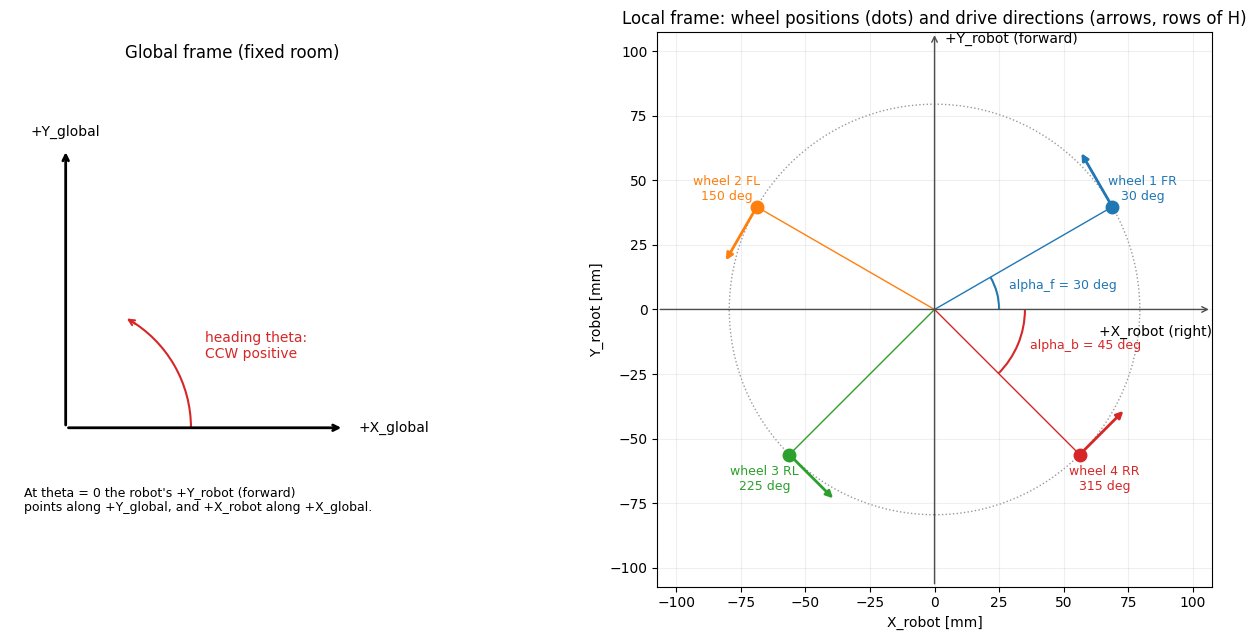

In [3]:
# Spatial reference frames and wheel layout, drawn from the model's own parameters (equal axes, so the angles are true)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc


def draw_layout(params):
    plant = OmniRobotSimulation(dict(params, sigma_V=0.0, sigma_mu=0.0))
    af, ab, Rb = params['alpha_f'], params['alpha_b'], params['Rb']
    beta = np.array([af, np.pi - af, np.pi + ab, 2.0 * np.pi - ab])       # wheel angles, CCW from +X_robot
    xy = Rb * 1e3 * np.column_stack((np.cos(beta), np.sin(beta)))         # wheel positions (mm)
    drive = plant.H[:, :2]                                               # drive direction of each wheel (rows of H)
    fig, (ax_g, ax) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 2]})

    # Global frame: X right, Y up; heading theta positive CCW
    ax_g.annotate("", xy=(1.0, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2))
    ax_g.annotate("", xy=(0, 1.0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2))
    ax_g.text(1.05, 0, "+X_global", va="center"); ax_g.text(0, 1.05, "+Y_global", ha="center")
    ax_g.add_patch(Arc((0, 0), 0.9, 0.9, theta1=0, theta2=60, color="C3", lw=1.5))
    ax_g.annotate("", xy=(0.45 * np.cos(np.radians(62)), 0.45 * np.sin(np.radians(62))),
                  xytext=(0.45 * np.cos(np.radians(55)), 0.45 * np.sin(np.radians(55))),
                  arrowprops=dict(arrowstyle="->", color="C3", lw=1.5))
    ax_g.text(0.5, 0.25, "heading theta:\nCCW positive", color="C3")
    ax_g.text(-0.15, -0.3, "At theta = 0 the robot's +Y_robot (forward)\npoints along +Y_global, and +X_robot along +X_global.", fontsize=9)
    ax_g.set(xlim=(-0.2, 1.4), ylim=(-0.45, 1.3), title="Global frame (fixed room)")
    ax_g.set_aspect("equal"); ax_g.axis("off")

    # Local frame: wheel positions and drive directions
    lim = 1.35 * Rb * 1e3
    ax.add_patch(plt.Circle((0, 0), Rb * 1e3, fill=False, ls=":", color="0.6"))
    ax.annotate("", xy=(lim, 0), xytext=(-lim, 0), arrowprops=dict(arrowstyle="->", color="0.3"))
    ax.annotate("", xy=(0, lim), xytext=(0, -lim), arrowprops=dict(arrowstyle="->", color="0.3"))
    ax.text(lim, -6, "+X_robot (right)", ha="right", va="top"); ax.text(4, lim, "+Y_robot (forward)", va="top")
    names = ("1 FR", "2 FL", "3 RL", "4 RR")
    for i in range(4):
        px, py = xy[i]
        ax.plot([0, px], [0, py], color=f"C{i}", lw=1)
        ax.plot(px, py, "o", color=f"C{i}", ms=9)
        ax.annotate("", xy=(px + 25 * drive[i, 0], py + 25 * drive[i, 1]), xytext=(px, py),
                    arrowprops=dict(arrowstyle="-|>", color=f"C{i}", lw=2))
        ax.text(px * 1.17, py * 1.17, f"wheel {names[i]}\n{np.degrees(beta[i]) % 360:.0f} deg", ha="center", va="center",
                color=f"C{i}", fontsize=9)
    # alpha_f and alpha_b, measured from the +X_robot axis
    afd, abd = np.degrees(af), np.degrees(ab)
    ax.add_patch(Arc((0, 0), 50, 50, theta1=0, theta2=afd, color="C0", lw=1.5))
    ax.text(30 * np.cos(np.radians(afd / 2)), 30 * np.sin(np.radians(afd / 2)), f"alpha_f = {afd:.0f} deg", color="C0", fontsize=9)
    ax.add_patch(Arc((0, 0), 70, 70, theta1=-abd, theta2=0, color="C3", lw=1.5))
    ax.text(40 * np.cos(np.radians(-abd / 2)), 40 * np.sin(np.radians(-abd / 2)), f"alpha_b = {abd:.0f} deg", color="C3", fontsize=9)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="X_robot [mm]", ylabel="Y_robot [mm]",
           title="Local frame: wheel positions (dots) and drive directions (arrows, rows of H)")
    ax.set_aspect("equal"); ax.grid(True, alpha=0.2)
    plt.tight_layout(); plt.show()


draw_layout(simulation_parameters)

# 🧪 Kinematic & Dynamic Verification Testing

This section executes open-loop verification trials to validate the electromechanical motor re-coupling, asymmetric kinematics mapping ($\mathbf{H}$), and stick-slip friction boundaries under hardware-verified sign directions. 

### 📐 Structural Testing Grid Architecture
The execution pipeline performs a **multi-block comparative analysis** across two distinct physical frame designs and environmental settings:
1. **Block 1: Symmetric Frame Verification:** Configures the plant layout to an identical 45° alignment across all wheel lines ($\alpha_f = 45^\circ$, $\alpha_b = 45^\circ$).
2. **Block 2: Asymmetric Frame Verification:** Reverts the plant setup back to your custom asymmetric layout ($\alpha_f = 30^\circ$, $\alpha_b = 45^\circ$).
3. **Block 3: Asymmetric Frame With Boosted Voltage Verification:** Keeps the asymmetric frame but boosts the voltage to operate the voltage is a more ideal range but also cause slipping. The previous two verifications focus on the voltage direction and general kinematic so voltage is very low.   

### 🕹️ Verification Test Input Sequences
To isolate each independent degree of freedom, the simulation applies precise step voltage patterns across the four wheel motors:
*   **Test 1: Forward Motion ($\mathbf{V} = [V, -V, -V, V]^\top$):** Applies positive voltages to the right-side motors ($1, 4$) and negative voltages to the left-side motors ($2, 3$). This drives all wheels to push the ground backward symmetrically, canceling out lateral side forces and accelerating the robot straight ahead along its local $+Y_r$ axis.
*   **Test 2: Lateral Side-Strafing ($\mathbf{V} = [-V, -V, V, V]^\top$):** Applies negative voltages to the front axle motors ($1, 2$) and positive voltages to the rear axle motors ($3, 4$). This mirrors the longitudinal forces across the front-to-back split line, causing forward and backward vectors to cancel out. The remaining lateral components combine to push the chassis cleanly sideways to the right along its local $+X_r$ axis.
*   **Test 3: Pure Rotational Spinning ($\mathbf{V} = [V, V, V, V]^\top$):** Applies uniform positive voltages to all four wheels simultaneously. Because every omni-wheel is mounted tangentially to the chassis base circle, spinning them all in the same rotational direction eliminates all linear translation vectors and creates a pure angular torque, spinning the robot counter-clockwise ($+\theta$) around its Center of Mass.

### 🔄 Dual-Pass State Conditions
To clearly isolate the degradation caused by environmental disturbances, each vehicle geometry executes a sequential dual-pass simulation:
*   **Ideal Pass (Reference Baseline):** Strips all noise configurations ($\sigma_V = 0.0$, $\sigma_\mu = 0.0$). The results render as soft, transparent curves representing perfect theoretical trajectories.
*   **Perturbed Pass (Real-World Overlay):** Activates a repeatable, seeded random number generator stream (`np.random.default_rng`) to overlay high-frequency structural chassis vibrations ($w_F$) and spatial friction coefficient patches ($w_\mu$).

### 📊 Logged Telemetry Variables
Each configuration runs the three directional maneuvers back-to-back over a 0.5-second time window (500 discrete calculation steps) and generates a standalone 2x2 grid capturing:
*   **Applied Motor Terminal Voltages ($V_{1\dots4}$):** Verifies step-input directional polarities.
*   **Wheel Angular Velocities ($\omega_{1\dots4}$):** Monitors electromechanical back-EMF variations and independent rotor spinout integrations ($J_w$).
*   **Chassis Local Frame Speeds ($\dot{x}_r, \dot{y}_r, \dot{\theta}$):** Evaluates translational and angular momentum unbalances inside the mass matrix universe ($\mathbf{M}^{-1}\mathbf{H}^\top\mathbf{F}_k$).
*   **Global Position Tracking ($X-Y$ Trajectory Plane):** Visualizes dead-reckoning coordinate transformation drift paths directly overlaying ideal performance vs. noisy tracking realities.

Executing Block 1: Symmetric 45-45 Wheel Angle Configurations...


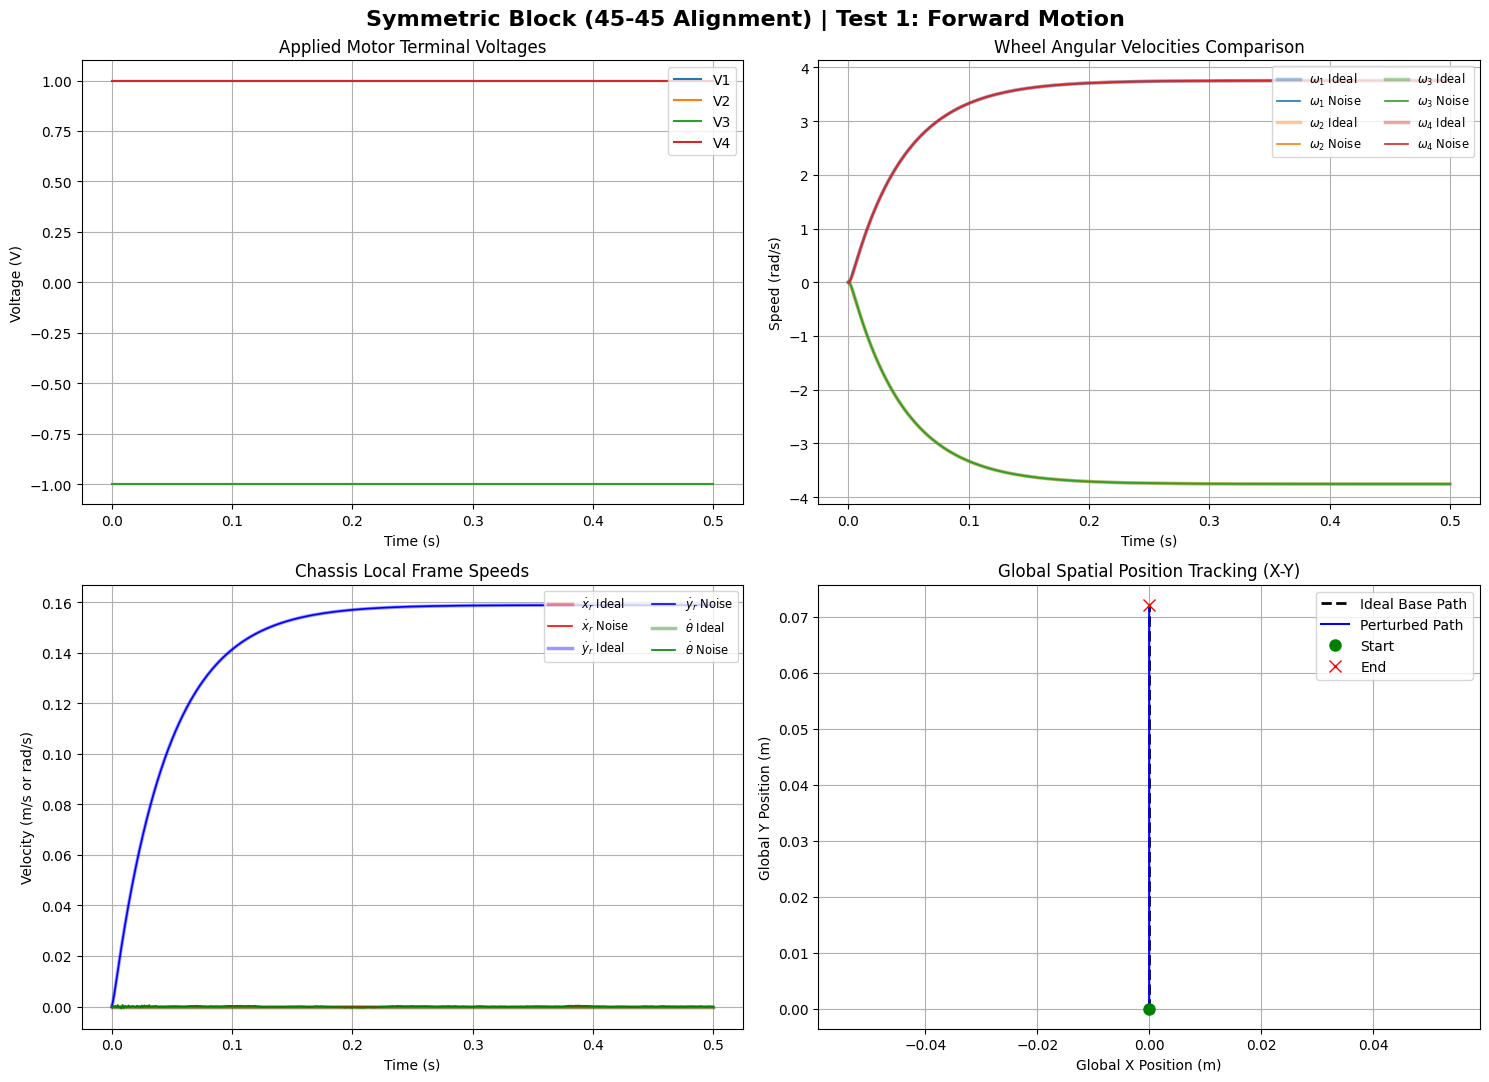

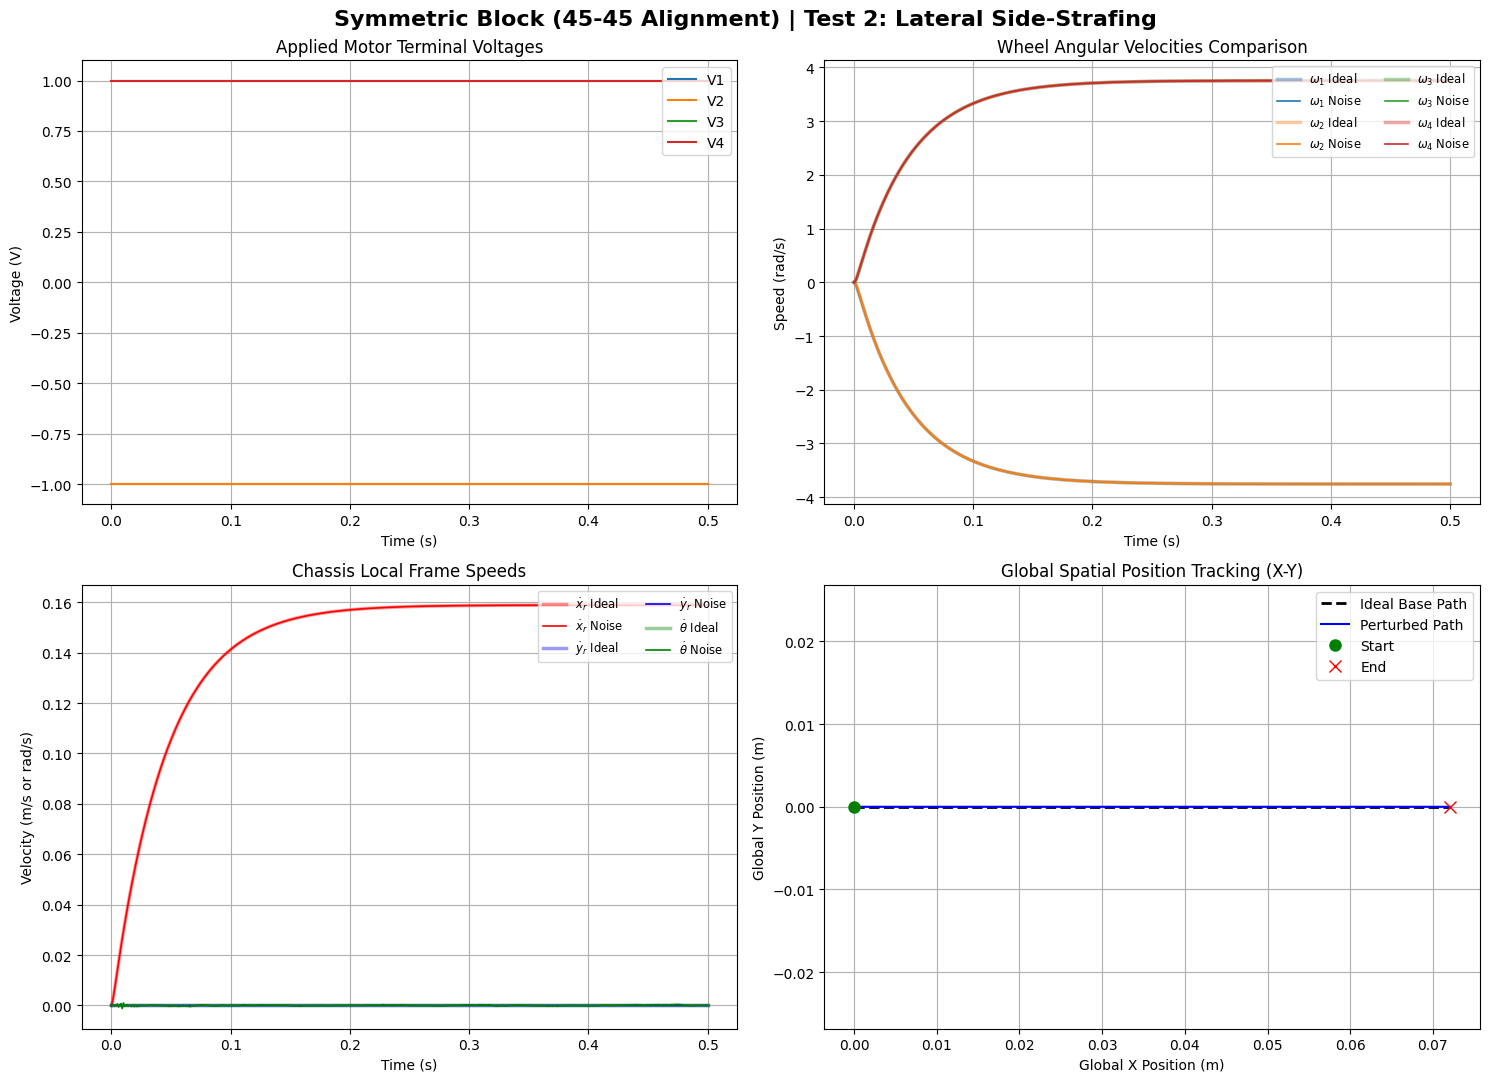

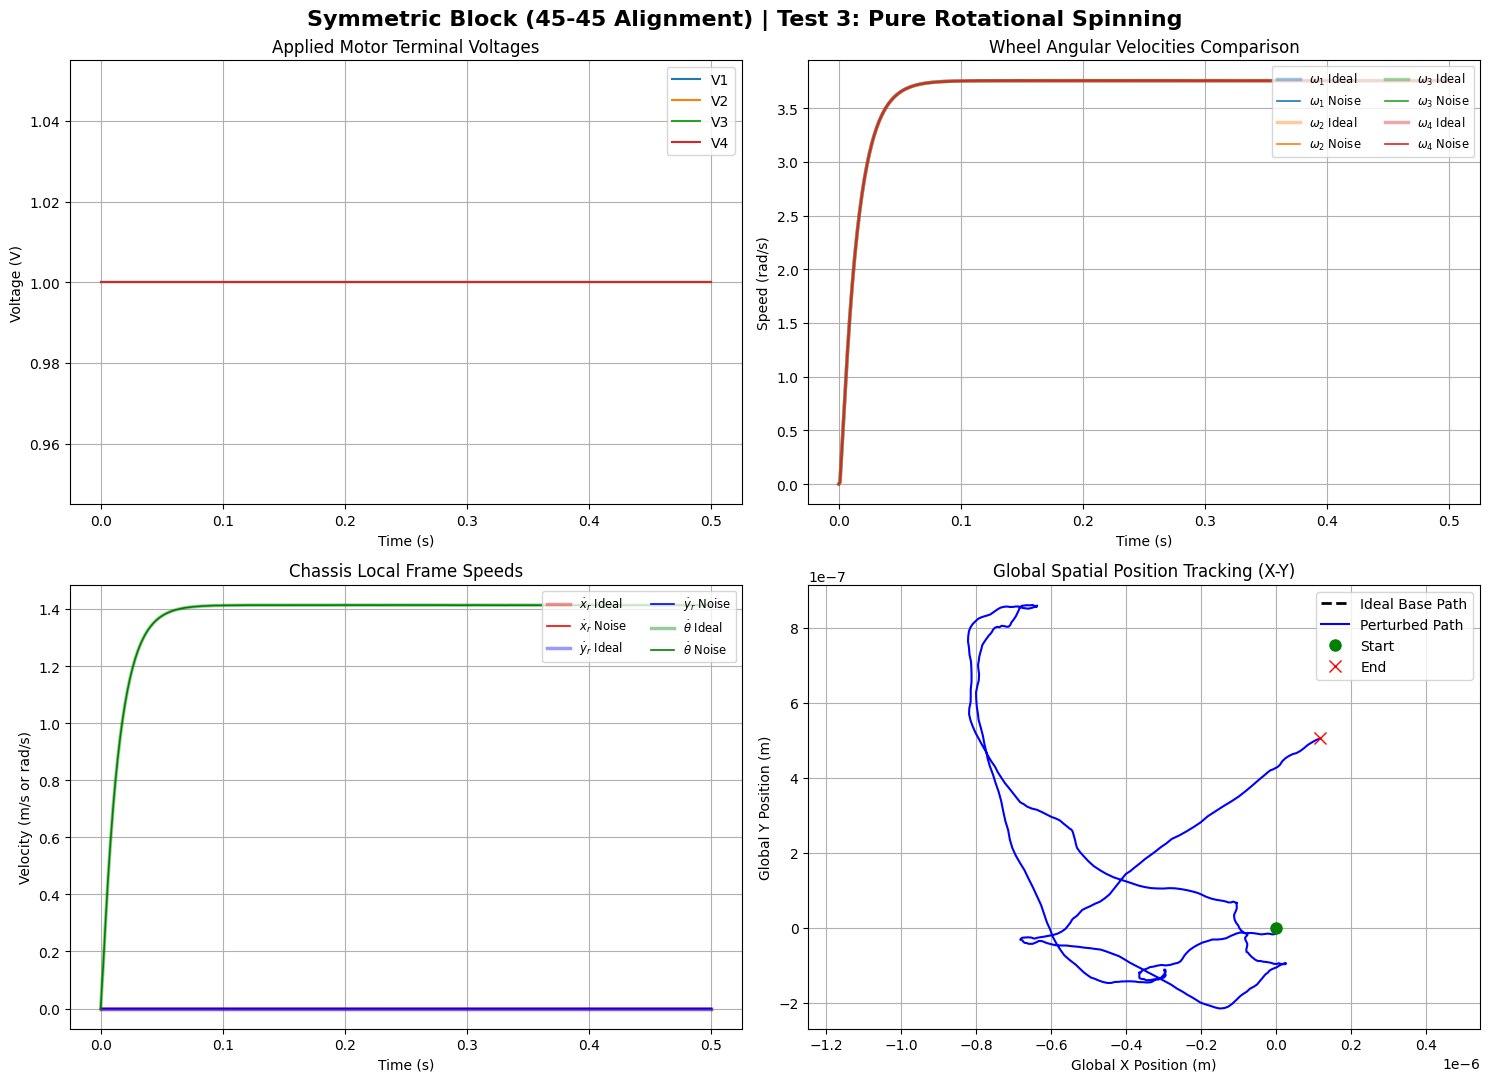

In [4]:
import numpy as np
import matplotlib.pyplot as plt

nominal_sigma_V = simulation_parameters['sigma_V']
nominal_sigma_mu = simulation_parameters['sigma_mu']

t_end = 0.5  
dt = simulation_parameters['dt']
steps = int(t_end / dt)
t_vec = np.linspace(0, t_end, steps)

low_voltage = 1
maneuvers = [
    {"name": "Test 1: Forward Motion", "V": np.array([low_voltage, -low_voltage, -low_voltage, low_voltage])},
    {"name": "Test 2: Lateral Side-Strafing", "V": np.array([-low_voltage, -low_voltage, low_voltage, low_voltage])},
    {"name": "Test 3: Pure Rotational Spinning", "V": np.array([low_voltage, low_voltage, low_voltage, low_voltage])}
]

# REMOVED redundancy: line style 'ls' is isolated out of the style modifiers
style_ideal = {'alpha': 0.4, 'lw': 2.5}  
style_noisy = {'alpha': 1.0, 'lw': 1.2}  

# CONFIGURATION CHANGE: FORCE SYMMETRIC 45-45 DESIGN
simulation_parameters['alpha_f'] = np.radians(45.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Block 1: Symmetric 45-45 Wheel Angle Configurations...")

for m in maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Symmetric Block (45-45 Alignment) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds (FIXED: Raw string notation used)
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities (FIXED: Isolated style configuration)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()


Executing Block 2: Asymmetric 30-45 Wheel Angle Configurations...


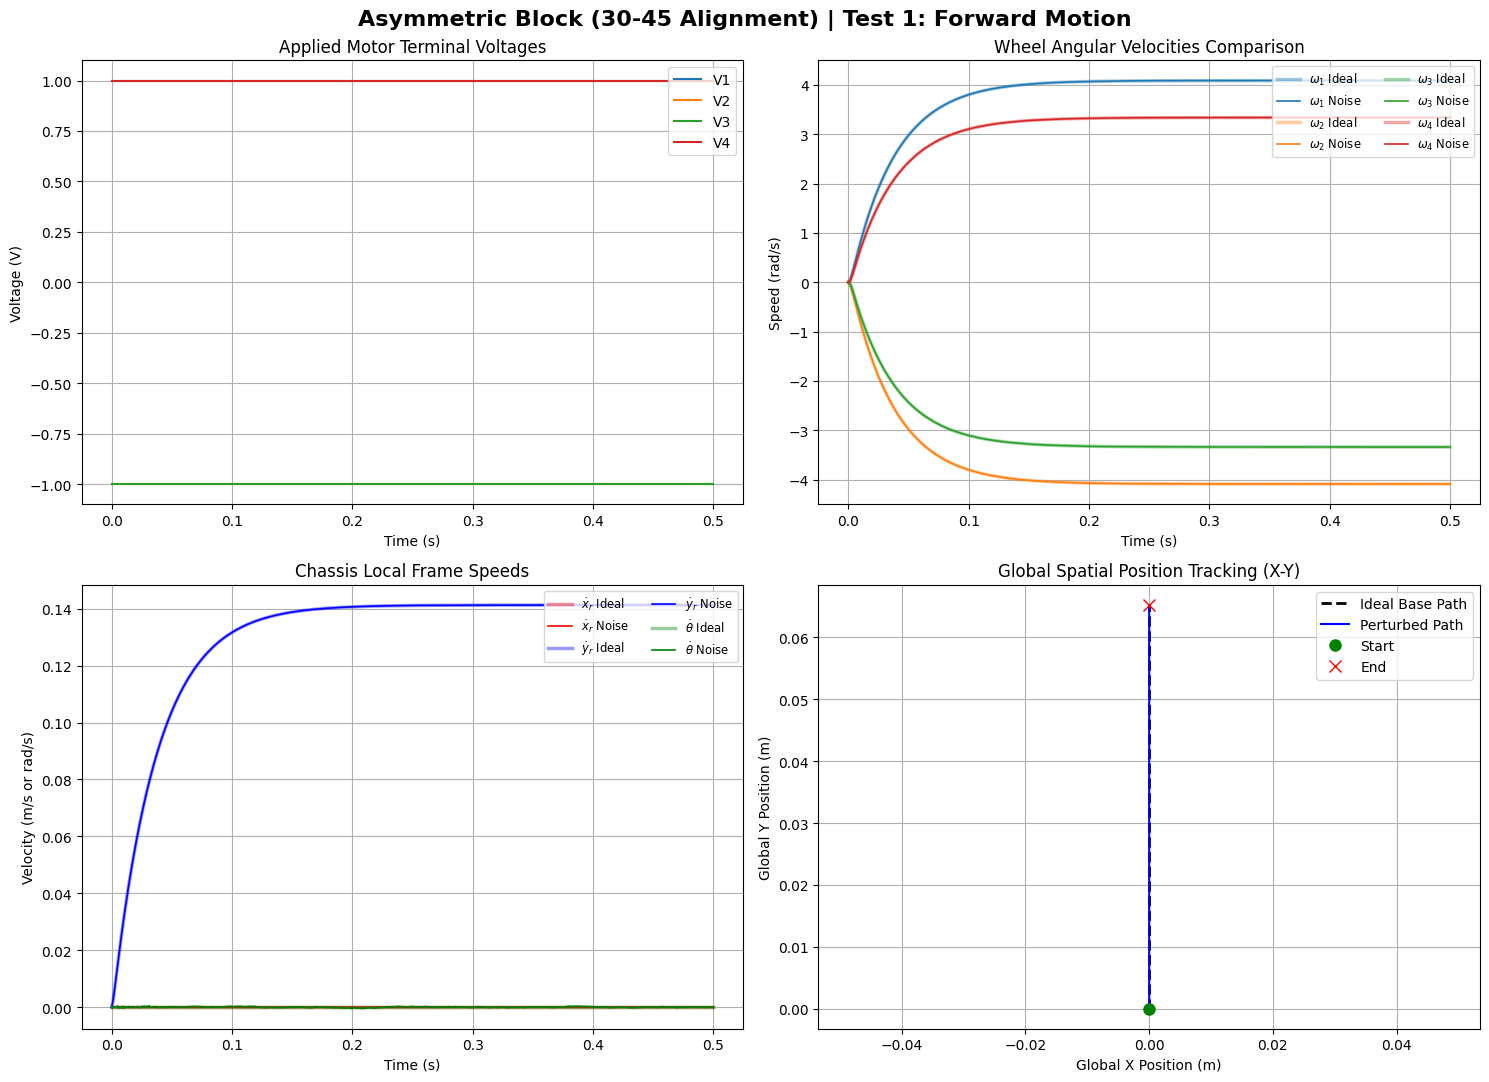

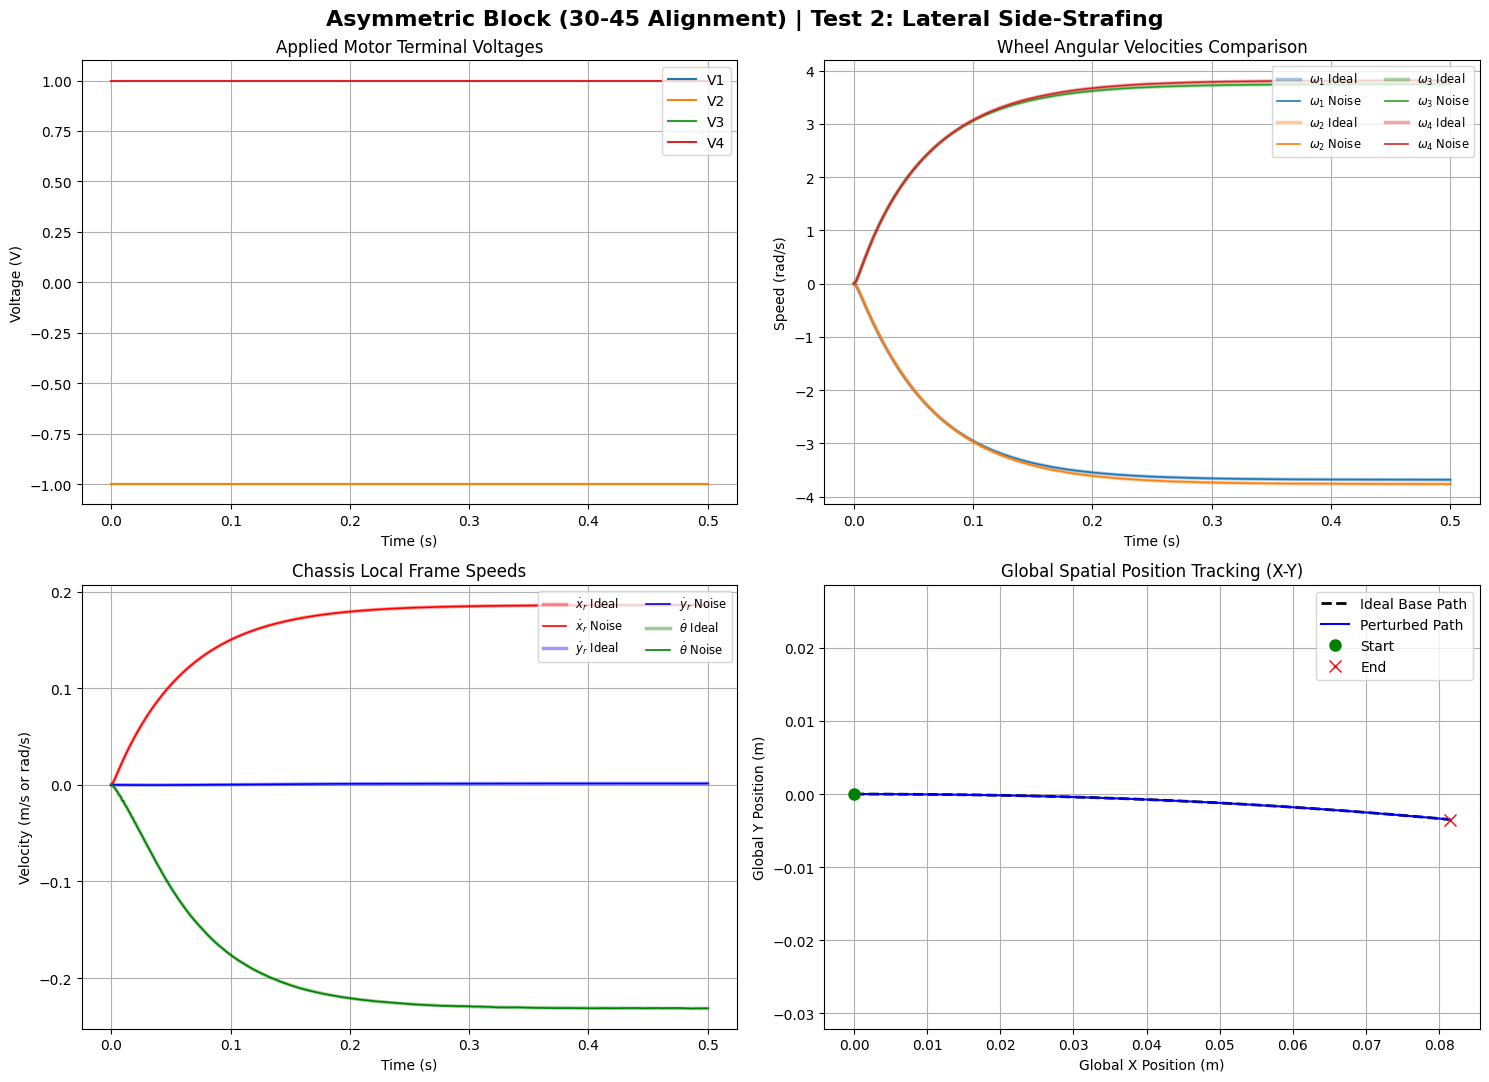

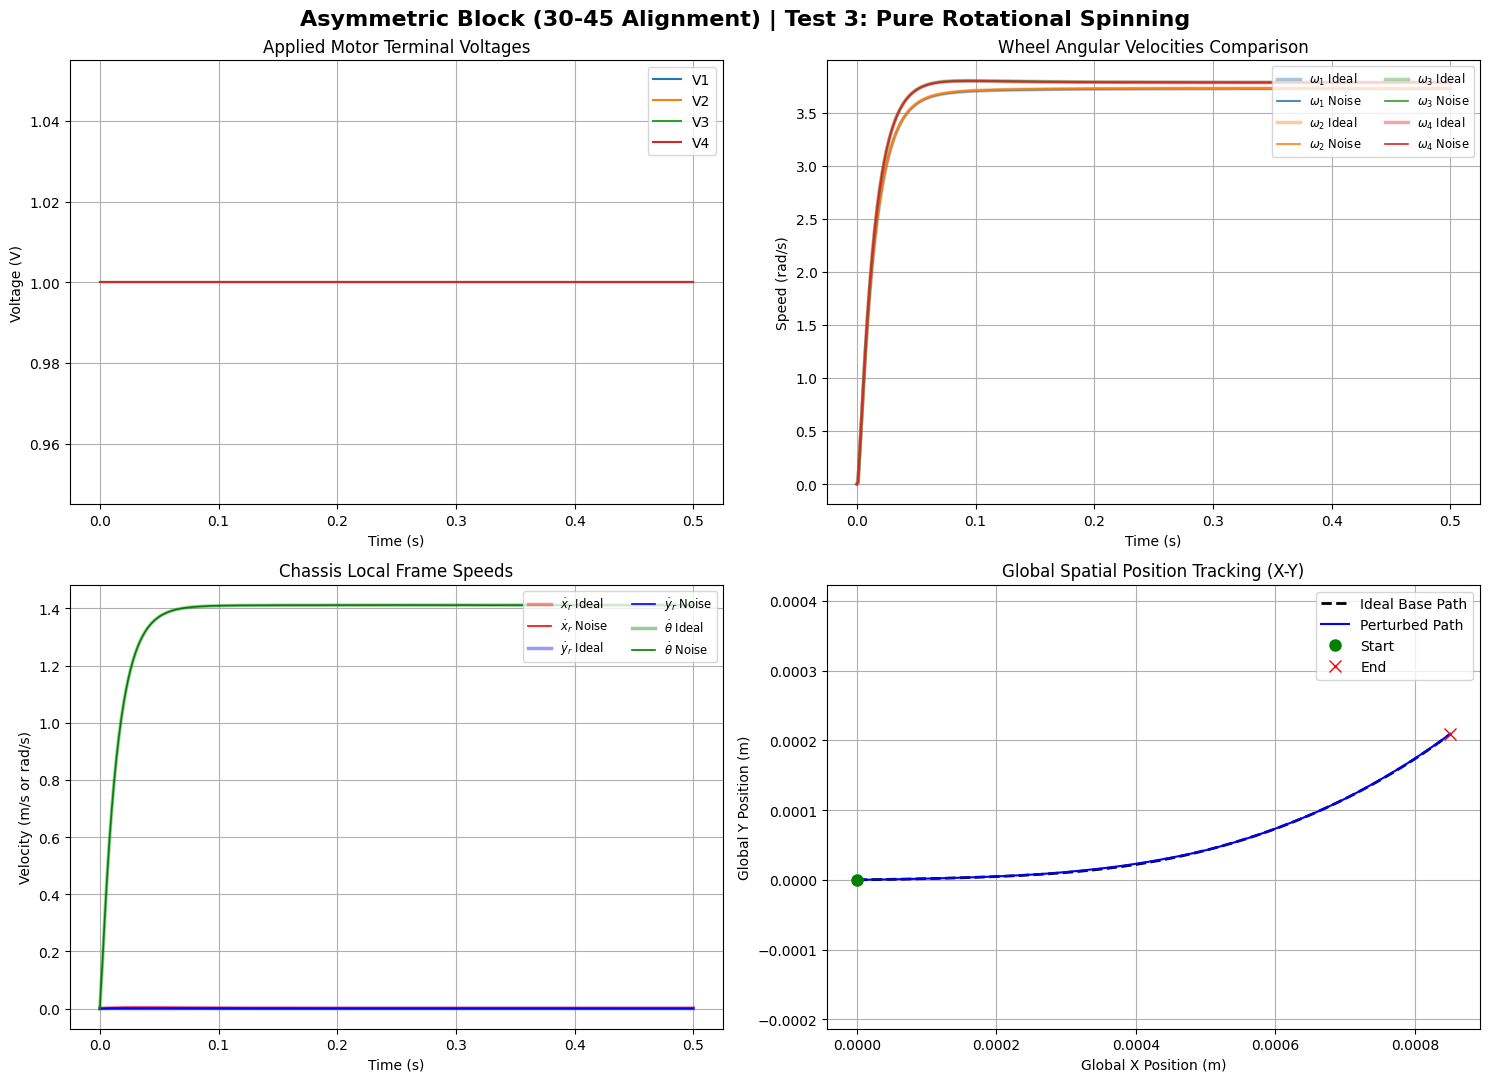

In [5]:
# CONFIGURATION CHANGE: REVERT TO ASYMMETRIC 30-45 DESIGN
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Block 2: Asymmetric 30-45 Wheel Angle Configurations...")

for m in maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric Block (30-45 Alignment) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds (FIXED: Raw string notation used)
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities (FIXED: Line parameters isolated)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Safely restore baseline parameter noise variables back to configuration dictionary
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu


Executing Block 3: Asymmetric 30-45 Wheel Angle Configurations at High Voltage (5.0V)...


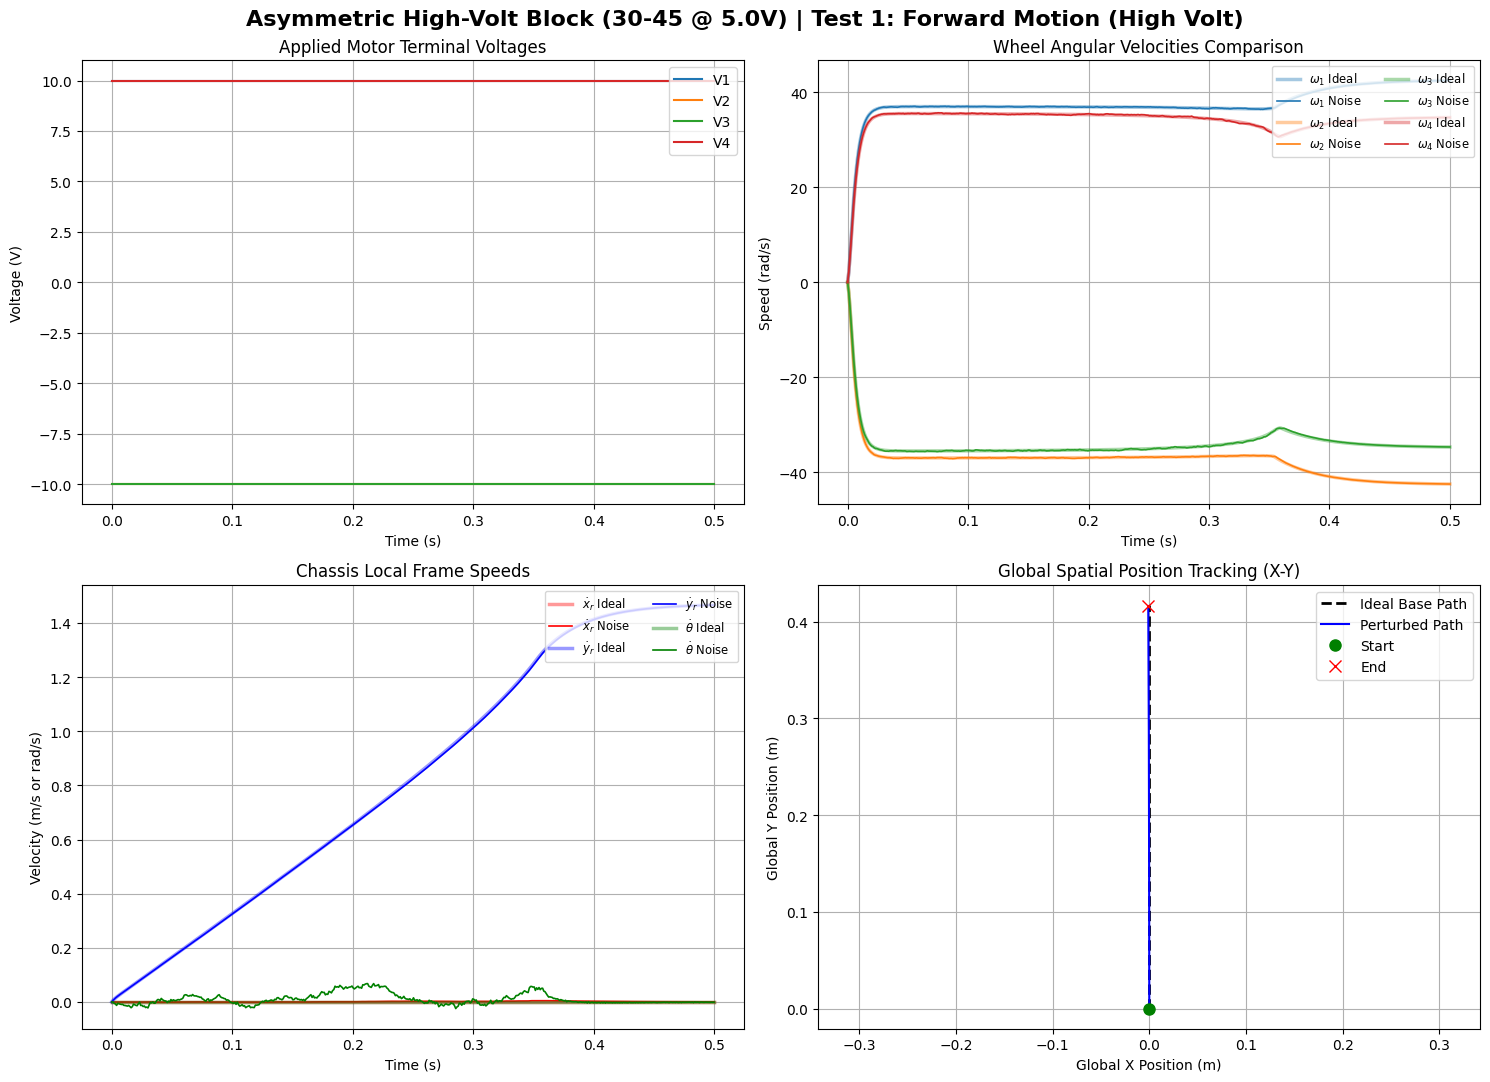

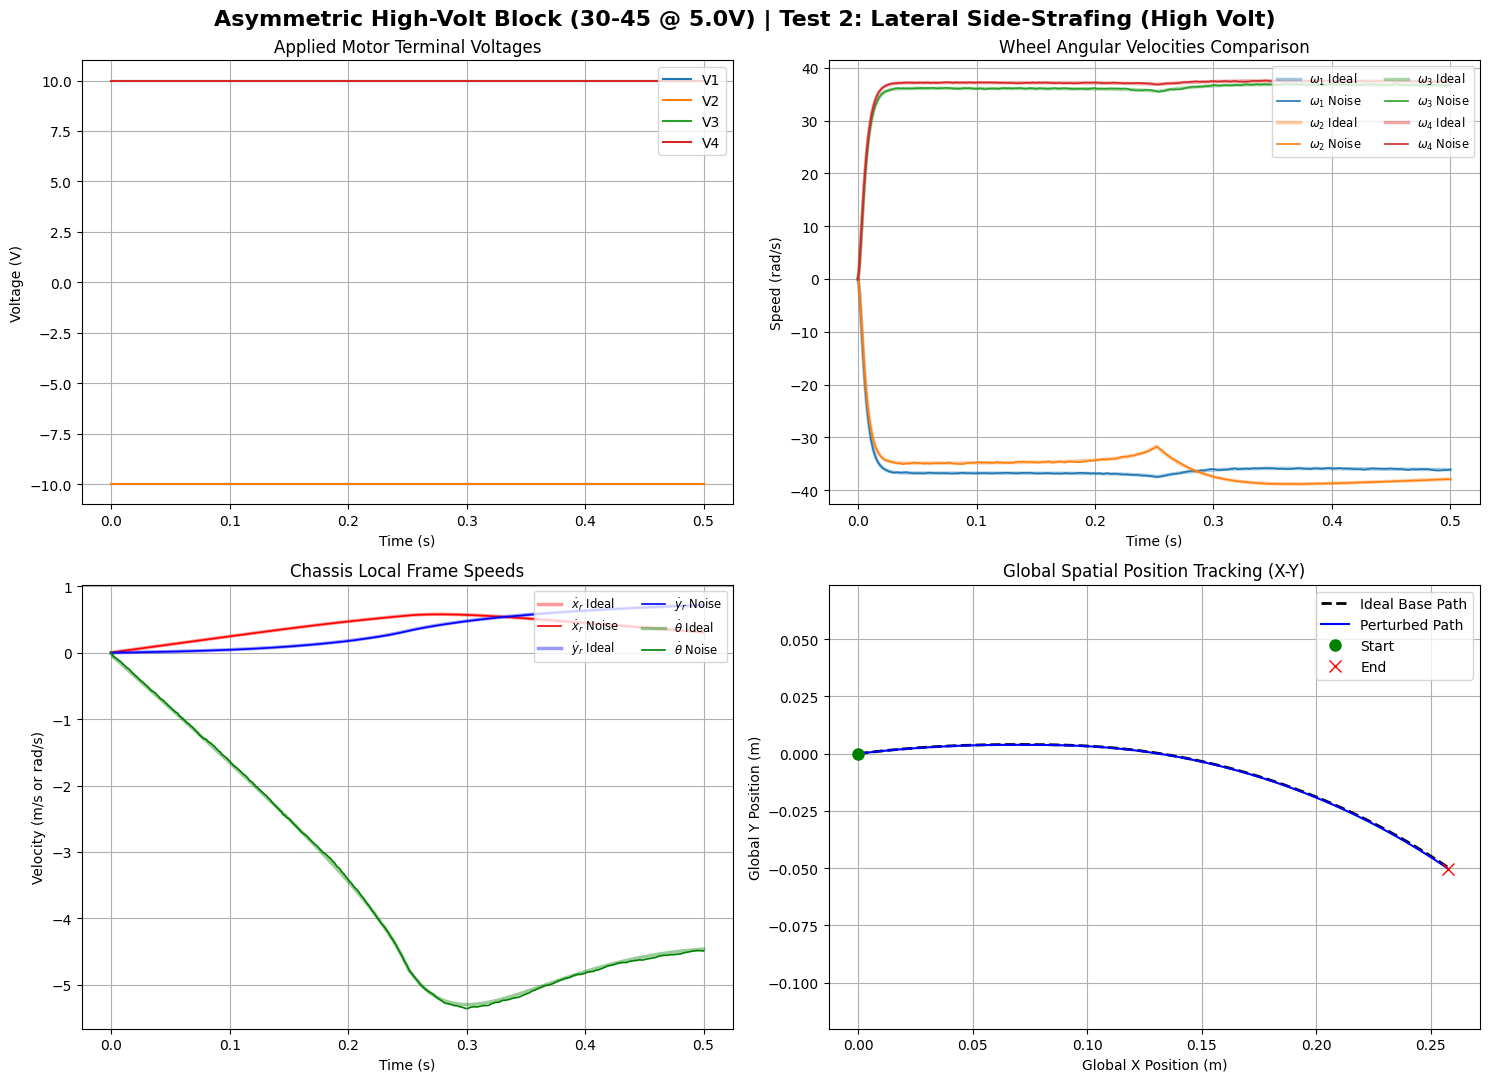

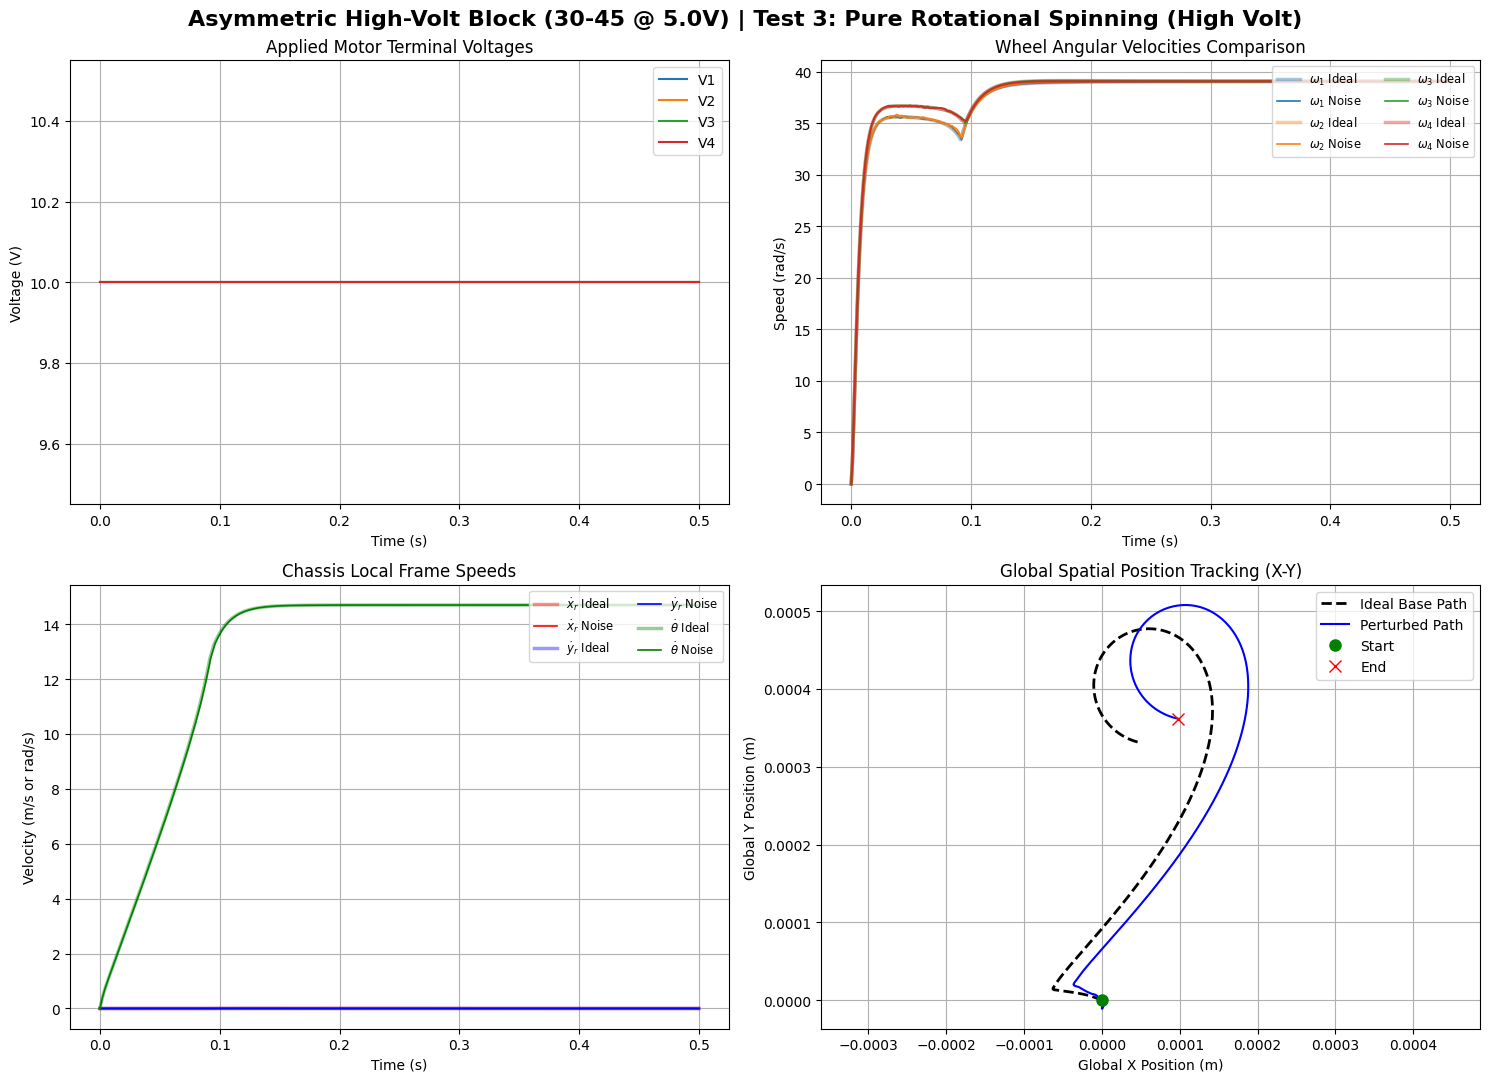

In [6]:
# =======================================================================
# CONFIGURATION CHANGE: KEEP ASYMMETRIC 30-45 DESIGN BUT BOOSTED VOLTAGE
# =======================================================================
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

bost_voltage = 10.0

# Define high-voltage directional maneuvers matching your verified sign choices
high_volt_maneuvers = [
    {"name": "Test 1: Forward Motion (High Volt)", "V": np.array([bost_voltage, -bost_voltage, -bost_voltage, bost_voltage])},
    {"name": "Test 2: Lateral Side-Strafing (High Volt)", "V": np.array([-bost_voltage, -bost_voltage, bost_voltage, bost_voltage])},
    {"name": "Test 3: Pure Rotational Spinning (High Volt)", "V": np.array([bost_voltage, bost_voltage, bost_voltage, bost_voltage])}
]

print("Executing Block 3: Asymmetric 30-45 Wheel Angle Configurations at High Voltage (5.0V)...")

for m in high_volt_maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        # Instantiate plant under custom asymmetric high-volt conditions (Seeded for reproducibility)
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric High-Volt Block (30-45 @ 5.0V) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Final safe restoration of baseline parameter noise variables back to dictionary
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu


# 🧪 Multi-Stage Sequence Verification Testing

This section executes verification routines using a **Multi-Stage Step Profile Timeline**. Each directional maneuver commands a voltage profile divided into three 1.0-second stages (Positive Drive $\to$ Negative Plug-Braking $\to$ Zero Coasting). This explicitly evaluates the plant's transient response, deceleration dynamics, and LuGre continuous friction behavior without artificial velocity snapping or numerical chatter.


Executing Profile Tests under Asymmetric 30-45 Geometry...


C:\Users\Henry\AppData\Local\Temp\ipykernel_15656\2344114742.py:106: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
C:\Users\Henry\AppData\Local\Temp\ipykernel_15656\2344114742.py:107: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
C:\Users\Henry\AppData\Local\Temp\ipykernel_15656\2344114742.py:108: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "b-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_id

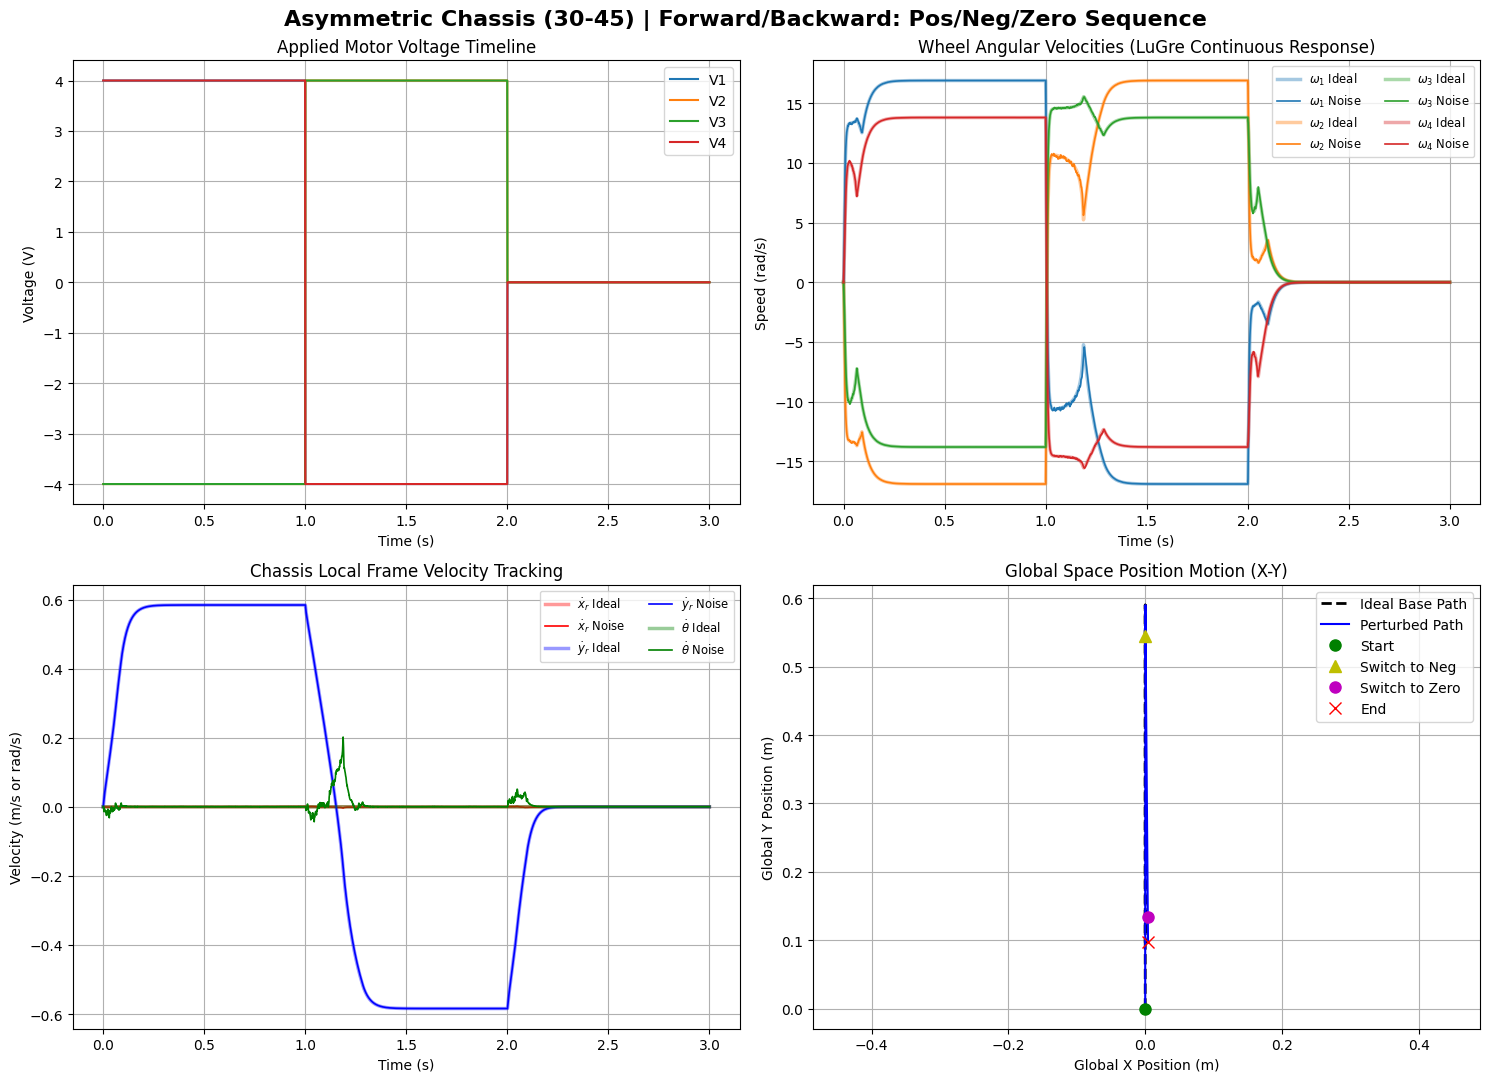

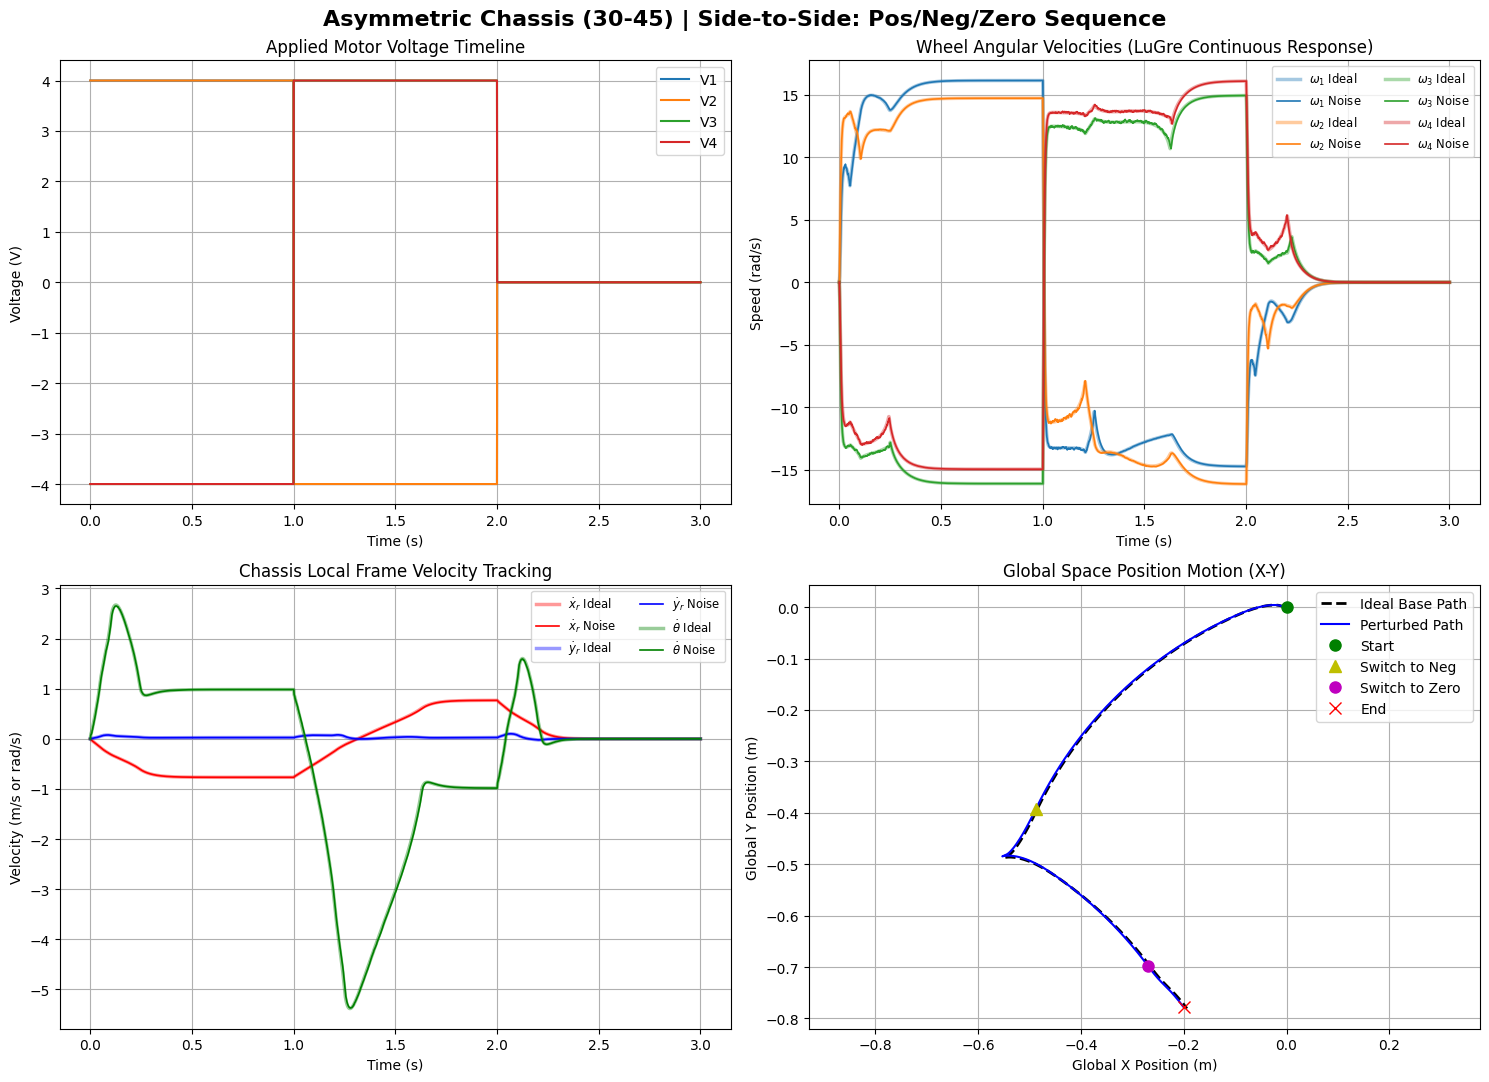

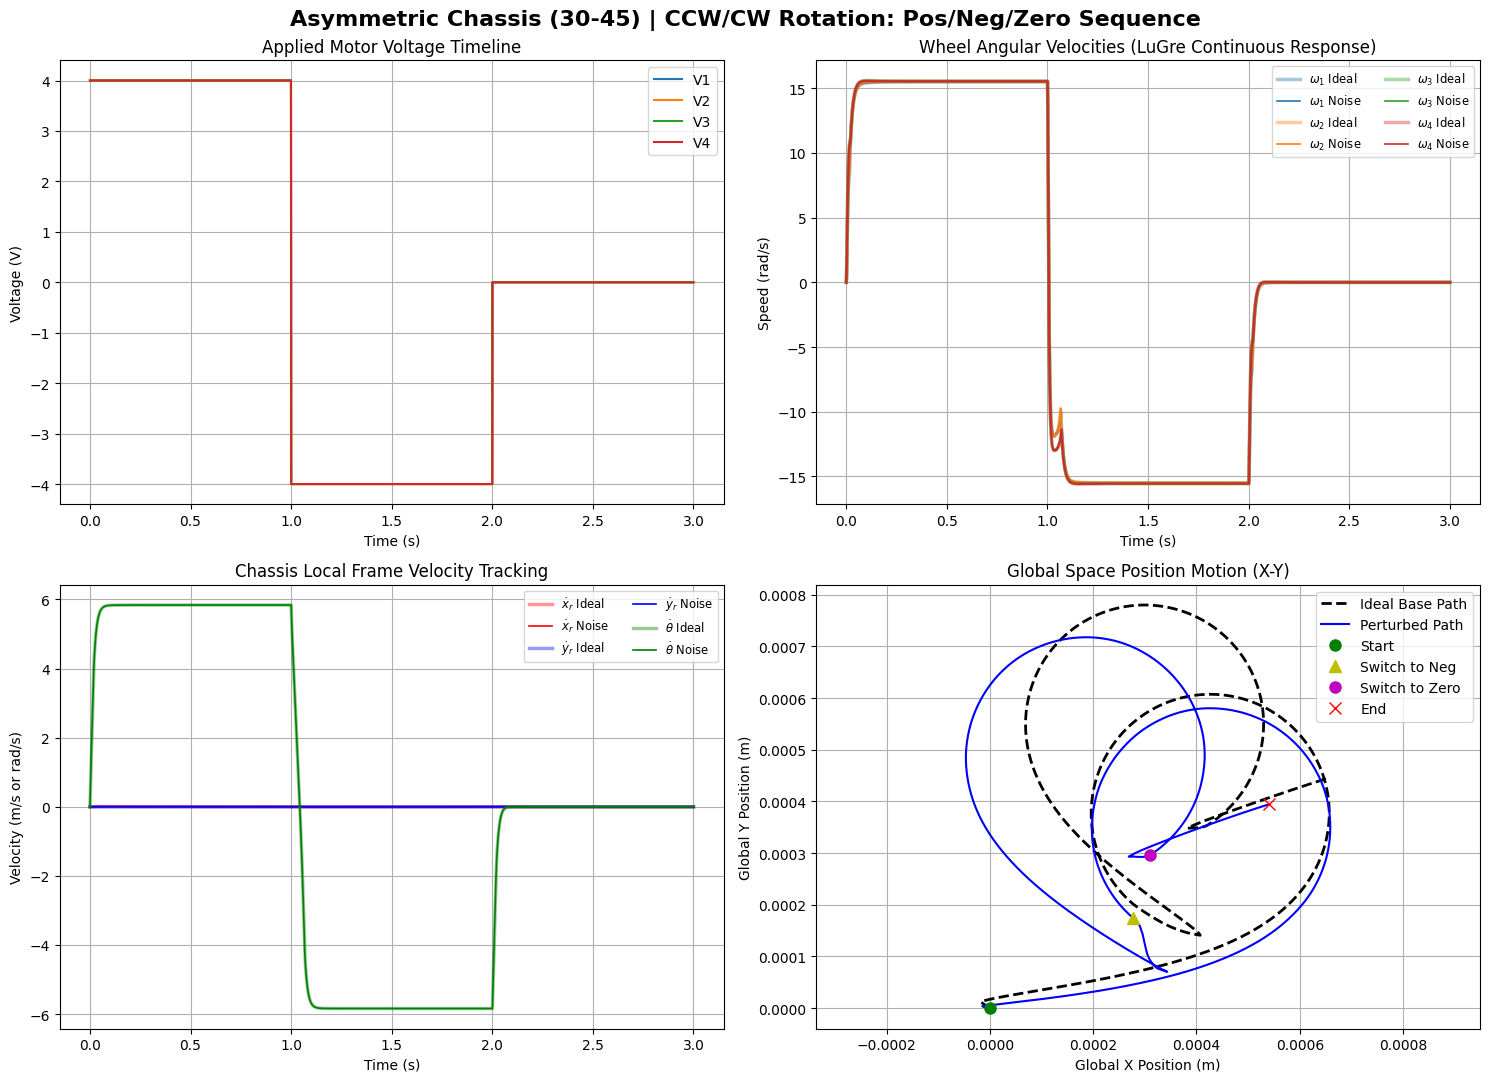

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Save your configured noise parameters to toggle the passes cleanly
nominal_sigma_V = simulation_parameters['sigma_V']
nominal_sigma_mu = simulation_parameters['sigma_mu']

# Define a 3.0 second timeline split into three distinct 1.0s intervals
t_stage = 1.0
dt = simulation_parameters['dt']
steps_per_stage = int(t_stage / dt)
total_steps = steps_per_stage * 3
t_vec = np.linspace(0, t_stage * 3, total_steps)

# Helper function to dynamically generate the voltage vector at any given step index k
def get_profile_voltage(test_type, step_idx, steps_per_stage):
    # Determine which chronological stage we are currently executing
    if step_idx < steps_per_stage:
        stage = "Positive"
        mag = 4.0
    elif step_idx < 2 * steps_per_stage:
        stage = "Negative"
        mag = -4.0
    else:
        stage = "Zero"
        mag = 0.0
        
    # Apply your verified hardware directional sign combinations scaled by stage magnitude
    if test_type == "Forward/Backward":
        return np.array([mag, -mag, -mag, mag])
    elif test_type == "Side-to-Side":
        return np.array([mag, mag, -mag, -mag])
    elif test_type == "CCW/CW Rotation":
        return np.array([mag, mag, mag, mag])
    return np.zeros(4)

# Define our three complex multi-stage test scenarios
test_scenarios = ["Forward/Backward", "Side-to-Side", "CCW/CW Rotation"]

# Plotting configuration styles
style_ideal = {'ls': '-', 'alpha': 0.4, 'lw': 2.5}  
style_noisy = {'ls': '-', 'alpha': 1.0, 'lw': 1.2}  

# =======================================================================
# STRUCTURAL RUN 1: ASYMMETRIC 30-45 CONFIGURATION WITH PROFILE MANEUVERS
# =======================================================================
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Profile Tests under Asymmetric 30-45 Geometry...")

for test_name in test_scenarios:
    runs_data = {}
    
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        # Step through the full 3.0 second timeline
        for k in range(total_steps):
            V_cmd = get_profile_voltage(test_name, k, steps_per_stage)
            
            v_in_hist.append(V_cmd.copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            
            state, T_load, S_status = robot_plant.step(state, V_cmd)
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    # -------------------------------------------------------------------
    # GENERATE 2x2 GRAPHS FOR COMPLEX PROFILE COUPLING
    # -------------------------------------------------------------------
    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric Chassis (30-45) | {test_name}: Pos/Neg/Zero Sequence", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Profiles (Now showing step changes over time)
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Voltage Timeline")
    axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds showing spikes during aggressive direction switches
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities (LuGre Continuous Response)"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Velocities showing Braking/Deceleration Curves
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Velocity Tracking"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane showing bidirectional path trace
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][steps_per_stage, 0], noisy["pos_global"][steps_per_stage, 1], 'y^', markersize=8, label='Switch to Neg')
    axs[1, 1].plot(noisy["pos_global"][2*steps_per_stage, 0], noisy["pos_global"][2*steps_per_stage, 1], 'mo', markersize=8, label='Switch to Zero')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Space Position Motion (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Restore baseline parameters securely
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu
